# 03b Perturbed: a perturbed copy of the CRAS model gives the verdicts known answers

**Slice.** The same room of the CRAS lab as 03a ("room B", the box in `01_cras_slice.json`, the 35 model elements that touch it, the 1 cm scan cache cut to the padded box). Here the model is the **perturbed model**: three walls moved by 1, 3 and 10 cm in an IFC copy, and three elements (one door, one element that is OK in the baseline, one wall with clutter in front of it) treated as deleted by leaving their scan points out of the comparison.

**Question.** When 03a's verdict logic, unchanged, is run on the perturbed model, does each injected change get the verdict it should (1 cm: OK, 3 and 10 cm: shifted, deleted: not confirmed), and how many untouched elements get flagged shifted or missing that should not (the input to the 05 gate: at most 10 %)?

Sections: (1) load, (2) the real model as baseline (03a's frame and verdicts, which must reproduce 03a's counts), (3) the perturbed IFC and its manifest: masks by geometry (with a synthetic known answer first), the choice of the deleted elements, a check that only the moved walls changed, (4) the perturbed run in the real model's frame, and what the masks leak, (5) the ICP pull: why refining against the perturbed model drags the frame, and the verdicts that frame would give, (6) scores, (7) outputs, then the answer. The baseline comes before the perturbation because the rules that pick the walls and the deleted elements use the baseline's assignment of scan points and verdicts.

**Changed after issue #18** (this notebook's first version is in the git history): the deleted masks are made by geometry instead of by the baseline's assignment; the perturbed run is scored in the **real model's** refined frame, not in a frame refined against the perturbed model (that drag is reported as its own finding, section 5); the column (0 scan points) is replaced, and the clutter-hidden wall is chosen by measured occlusion. The moved walls and their rule are unchanged.

**03a's logic is copied, not imported** (the roadmap keeps stage logic inline until it is formalised): the parameters, the crop, the ICP refinement, the room-facing wall offsets with the wall side test and the junction margin of 03a (issue #17: which side of a wall a point was seen from, and which points within `JUNCTION` of another element are left out; `occupancy`, `occupied_along`, `plane_vote`, `place_wall_points`, `measure`), `judge`. The parameters and rules are 03a's, wrapped in functions; exploration that the verdicts do not need (RANSAC check, residual tail, crop and sensitivity studies, winding table) is dropped. Nothing is tuned here: every parameter is 03a's.
Terms (scan, model, element, clutter, scan class, oracle labels, perturbed model, tolerance, verdict) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. Nothing is written outside `outputs/03b/` (gitignored); `data/` is only read.


In [1]:
import csv, dataclasses, json, os, resource, time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
import ifcopenshell
import ifcopenshell.util.placement as ifc_placement
import ifcopenshell.util.unit as ifc_unit
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# Parameters: 03a's, unchanged, with 03a's justification comments (03a's cross-references to its own sections kept as '03a's section N'). Lengths in metres.
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
SLICE = Path("01_cras_slice.json")  # written by notebook 01: recorded transform, room box, the 35 elements
OUT = Path("../outputs/03b")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)
PERTURBED_IFC = OUT / "craslabbim_perturbed.ifc"

CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")

TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in 03a's section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see 03a's section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.95  # LOA30 is "specified at the 95 % confidence level": 15 mm is at 2 sigma, so 95 % of an element's points must lie within it
                    # (00's toy used 0.8; 03a's section 4 shows that value too)
MIN_FRAC_CLUSTER = 0.8  # (judgement call, not from the standard) shifted: share of points within TOL of the element's median. Clutter and element edges
                        # leave a real offset plane only 78 to 94 % near its median on this room, so 95 % is too strict here; 0.8 still rejects a 55/45 bimodal wall
SIDE_NEAR, SIDE_FAR, SIDE_STEP = 0.03, 0.20, 0.02  # (judgement call) wall side test: look this far from a wall point along the thickness axis: beyond the point's own surface noise,
                                                    # past a 10 cm drywall's other face, short of most furniture. Steps are one occupancy voxel
OCC_VOXEL = 0.02  # (judgement call) occupancy grid voxel for the side test: 2 cm, about 35 MB as a dense bool array over the crop
VOTE_BIN = 0.005  # plane vote: 5 mm bins along the thickness axis; the window is TOL each side (VOTE_HALF bins)
VOTE_HALF = round(TOL / VOTE_BIN)
VOTE_SHARE = 0.5  # (judgement call) a plane takes the side that more than half of all its points show by themselves; 03a's section 3 gives the reason
JUNCTION = 0.10  # (judgement call) a wall point within this distance of any other element's surface (ceiling, floor, window, door, another wall) is left out of the wall's verdict:
                 # it is at a junction, and could belong to either element. 03a's section 3 gives the reason and the sensitivity (0, 5, 10, 15 cm)
MIN_AREA_IN_BOX = 0.10  # (judgement call) below this share of an element's surface inside the room box, the in-box part is too small to stand for the element
PROBE = 0.05  # (judgement call) a wall face is room-facing if the point this far outside it, along its normal, is within the room box's extent

N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
ICP_DIST = 0.10  # plain point-to-plane ICP
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05  # 03a's bounds on the ICP correction

# 03b: what is injected (decisions fixed before the run, see section 3)
OCC_NEAR, OCC_FAR = 0.03, 1.0  # (judgement call) clutter 'in front of' a wall face: clutter-class scan points from 3 cm (the side test's near limit, beyond the wall's own surface noise) to 1 m (furniture and a person's
                                 # reach; 0.5 m is printed too) away from it along its normal
OCC_FAR_SHORT = 0.5  # (judgement call) the shorter distance printed next to OCC_FAR, to see whether the ranking depends on it
OCC_SAMPLES_PER_M2 = 400  # (judgement call) surface samples per m2 of wall face for the clutter-in-front share (one every 5 cm)
OCC_BOX_MARGIN = 0.02  # (judgement call) face samples within this margin of the room box count (01's box faces sit within about 1 cm of the wall faces)
STRIDE = 8  # (judgement call) section 5's experiments use every 8th scan point to keep the run time down; the check line there compares it with the full scan
DY = np.arange(-15, 20.1, 2.5)  # (judgement call) section 5, experiment 2: scan shifts along y from the real-model frame, mm; spans both equilibria (0 and about 13) with margin
Z_CUT = 1.15  # section 7's plan figure: height of the cut, m (chest height)
MOVE_M = (0.01, 0.03, 0.10)  # three walls moved by these distances, into the room
EXPECTED_MOVED = {0.01: "OK", 0.03: "shifted", 0.10: "shifted"}  # absolute verdicts: 1 cm is inside the 15 mm tolerance, 3 and 10 cm are not
BASELINE_COUNTS = {"no_labels": {"OK": 5, "shifted": 1, "not confirmed": 29},  # 03a's answer: this notebook's copy of the logic must give them
                   "oracle_labels": {"OK": 7, "shifted": 1, "not confirmed": 27}}
BASE_TXT = " and ".join(" / ".join(str(v) for v in BASELINE_COUNTS[k].values()) for k in ("no_labels", "oracle_labels"))  # "5 / 1 / 29 and 7 / 1 / 27"

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

## 1. Load: the 35 room elements of the real model, then the scan cut to the room

As 03a section 1: the contract from notebook 01 (`frame.scan_to_model_4x4`, `room.box_model_frame`, the 35 GlobalIds), the 35 elements tessellated with `only_guids`, the scan cache transformed in chunks and cropped to the box padded by `PAD`. The crop is kept in the **recorded** frame (`P_REC`); each run applies its own ICP correction to it.

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (03a: no scanner positions on CRAS)

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS) and len(GUIDS) == 35, "not all 35 room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")

t = time.time()
cache = np.load(CACHE)
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P_REC = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P_REC >= box_lo) & (P_REC <= box_hi)).all(1)
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
element_ids = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
is_element_class = np.isin(SCAN_CLASS, element_ids)
is_clutter_class = ~is_element_class & (SCAN_CLASS != CLASS_NAMES.index("unassigned"))  # 03b: a scan class that is neither an element's nor 'unassigned'
print(f"cache {n_total:,} points -> {len(P_REC):,} in the box padded by {PAD * 100:.0f} cm ({time.time() - t:.0f} s); "
      f"element scan classes {is_element_class.sum():,}, clutter classes {is_clutter_class.sum():,}, unassigned {(SCAN_CLASS == 0).sum():,}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

35 elements tessellated in 23 s, 195,576 triangles


cache 20,404,814 points -> 4,065,952 in the box padded by 10 cm (2 s); element scan classes 2,553,125, clutter classes 946,300, unassigned 566,527
peak RSS so far: 1.05 GB


## 2. The real model as baseline: 03a's frame and verdicts

Everything in this section is 03a's logic, wrapped in functions (`icp_target`, `refine`, `assign`, `verdict_rows`) with the same parameters and rules, which the baseline-count assert below checks: ICP refinement from the recorded transform (plain point-to-plane, then a Tukey robust pass, **all** room points, no labels, against points sampled on the model's 35 elements); every crop point assigned to the nearest element; the signed offset (for walls measured against the room-facing faces on the side each point was seen from, with the neighbouring room's surface and the points within `JUNCTION` of another element left out, see 03a); `judge` for the verdict. Because it is written as functions of the model, section 4 runs the very same code on the perturbed model.

The baseline must reproduce 03a's counts (without labels 5 OK / 1 shifted / 29 not confirmed; with labels 7 / 1 / 27); that is asserted below, so any difference between this copy and 03a is caught.

In [3]:
# ---- 03a's logic, copied and wrapped in functions (same parameters and rules; the baseline-count assert checks it) ------------------------------------------------------------------------------------------
def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def icp_target(els):
    # Points sampled on the elements (all faces), kept within MODEL_CLIP of the box; and the centroid of those within the scan crop.
    o3d.utility.random.seed(SEED)
    sampled = merge_meshes(els).sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
    q = np.asarray(sampled.points)
    target = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))
    q = np.asarray(target.points)
    return target, q[((q >= crop_lo) & (q <= crop_hi)).all(1)].mean(0)


def refine(points, target):
    # ICP from the recorded transform: the scan is already in the model frame under T_REC, so ICP starts at the identity and its result
    # is the correction in the model frame: T_refined = correction @ T_REC.
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, target, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, target, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def judge(s, area_frac=1.0, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # One element's verdict from its signed offsets s (metres, within BAND) and the share of its surface inside the box.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma, informational only
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    one_cluster = float(np.mean(np.abs(s - median) <= TOL)) if n else 0.0  # share of points within TOL of the median
    if area_frac < MIN_AREA_IN_BOX:
        verdict, reason = "not confirmed", "mostly outside the room box"
    elif n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and one_cluster >= min_cluster:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share,
                cluster_share=one_cluster)


def room_facing(e, lo, hi):
    # Boolean per triangle of a wall: vertical faces whose outward normal points into the box [lo, hi] (plan view); the box is taken along the
    # normal only, because a wall runs on beyond the box and its triangles there still face the same way.
    n = np.asarray(mesh_of(e).triangle_normals)
    probe = e.vertices[e.faces].mean(1) + PROBE * n
    a, b = n[:, :2] * lo[:2], n[:, :2] * hi[:2]
    s = (probe[:, :2] * n[:, :2]).sum(1)
    return (np.abs(n[:, 2]) < 0.5) & (s >= np.minimum(a, b).sum(1)) & (s <= np.maximum(a, b).sum(1))


def closest_signed(scene, normals, first, pts):
    # Nearest triangle of the scene to each point: its geometry id, the distance, and the offset along that triangle's normal.
    geom, dist, signed = np.empty(len(pts), np.int32), np.empty(len(pts), np.float32), np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 500_000):
        p = np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32)
        r = scene.compute_closest_points(o3d.core.Tensor(p))
        g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
        geom[i:i + 500_000] = g
        dist[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
        signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, normals[first[g] + prim])
    return geom, dist, signed


# How place_wall_points decided a point's side
HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS = 1, 2, 3  # its own free space; its plane's side; neither (the nearest room-facing face decides)


def occupancy(pts):
    # Dense boolean grid over the points' bounding box: True where a voxel of OCC_VOXEL holds at least one scan point.
    lo = pts.min(0).astype(np.float64)
    grid = np.zeros(np.ceil((pts.max(0) - lo) / OCC_VOXEL).astype(int) + 1, bool)
    j = np.floor((pts - lo) / OCC_VOXEL).astype(int)
    grid[j[:, 0], j[:, 1], j[:, 2]] = True
    return lo, grid


def occupied_along(occ, p, axis, sign):
    # Per point: is any voxel occupied from SIDE_NEAR to SIDE_FAR away along sign * axis? Outside the grid counts as free.
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(SIDE_NEAR, SIDE_FAR + 1e-9, SIDE_STEP):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def plane_vote(u, facing, share):
    # Per point: the side its surface plane shows as a whole, or 0. u: the points' coordinate along the wall's thickness axis; facing: what each
    # point shows by itself (1, -1 or 0). A plane is the points within TOL of u (VOTE_HALF bins of VOTE_BIN each side); it takes a side if more than
    # `share` of all its points show that side by themselves.
    b = np.floor((u - u.min()) / VOTE_BIN).astype(int)
    window = np.ones(2 * VOTE_HALF + 1)
    count = lambda m: np.convolve(np.bincount(b[m], minlength=max(b.max() + 1, window.size)), window, "same")[b]  # np.convolve "same" returns the longer input: pad to the window
    total, plus, minus = count(np.ones(len(u), bool)), count(facing == 1), count(facing == -1)
    return np.where(plus > share * total, 1, np.where(minus > share * total, -1, 0))


def place_wall_points(e, face_set, p, fallback, occ, vote_share=VOTE_SHARE):
    # The scan points p (assigned to wall e, within BAND) -> their signed offsets along the reference side's normal, NaN for the points that are the
    # back of the wall; `fallback` is the offset by the nearest room-facing face (the rule before the side test), used where the side is ambiguous.
    # Returns the offsets, how each point was decided (HOW_OWN: free space on one side only, HOW_PLANE: its plane's side, HOW_AMBIGUOUS: fallback) and a dict of counts.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))  # the thickness axis in plan
    assert np.all(np.minimum(np.abs(n[face_set, 0]), np.abs(n[face_set, 1])) < 1e-3), "a wall is not aligned with the model axes"
    broad = {s: face_set & (n[:, a] * s > 0.99) for s in (1, -1)}  # the wall's two big faces (end faces left out), by the sign of their normal along the axis
    sides = [s for s in (1, -1) if broad[s].any()]  # room-facing sides: 1 for a boundary wall, 2 for a partition inside the box
    assert sides, "a wall has no room-facing side"
    free_plus, free_minus = ~occupied_along(occ, p, a, +1), ~occupied_along(occ, p, a, -1)
    own = np.where(free_plus & ~free_minus, 1, np.where(~free_plus & free_minus, -1, 0))  # the direction the surface was seen from; 0: ambiguous
    plane = plane_vote(p[:, a], own, vote_share) if vote_share is not None else np.zeros(len(p), int)  # vote_share None: no plane vote
    facing = np.where(plane != 0, plane, own)  # a plane that most of its own points see from one side takes that side, also from the ones that say otherwise
    off = {}  # per room-facing side: the offset to that side's faces, along its outward normal
    for s in sides:
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[broad[s]]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, n[broad[s]], np.zeros(1, int), p)
        off[s] = np.copysign(d_face, s_face)
    side = np.zeros(len(p), int)  # the room-facing side each point is measured against
    dropped = np.zeros(len(p), bool)  # seen from a side that is not room-facing: the neighbouring room's surface
    for s in (1, -1):
        if s in sides:
            side[facing == s] = s
        else:
            dropped |= facing == s
    ambiguous = facing == 0
    side[ambiguous] = np.where(np.abs(off[1][ambiguous]) <= np.abs(off[-1][ambiguous]), 1, -1) if len(sides) == 2 else sides[0]
    n_side = {s: int(((side == s) & ~dropped).sum()) for s in sides}
    ref = sides[0] if len(sides) == 1 else (1 if n_side[1] >= n_side[-1] else -1)  # reference side: the one with more points, ties to +axis
    sign = np.where(side == ref, 1.0, -1.0)  # the other side's offsets are flipped onto the reference normal
    signed = np.where(ambiguous, fallback, np.where(side == 1, off[1] if 1 in sides else 0, off[-1] if -1 in sides else 0)) * sign
    signed = signed.astype(np.float32)
    signed[dropped] = np.nan
    how = np.where(ambiguous, HOW_AMBIGUOUS, np.where(facing == own, HOW_OWN, HOW_PLANE)).astype(np.int8)
    info = dict(axis=a, sides=sides, ref=ref, n_band=len(p), n_dropped=int(dropped.sum()), n_ambiguous=int(ambiguous.sum()), n_side=n_side,
                n_by_plane=int((how == HOW_PLANE).sum()), n_overruled=int(((own != 0) & (facing != own)).sum()))
    return signed, how, info


def apply_junction(signed_side, d_other, junction):
    # The one place where the junction margin is applied: the offsets with NaN where a point is within `junction` of another element's surface (d_other is NaN for
    # points that are not a wall's, so they are never touched; junction None: no margin).
    s = signed_side.copy()
    if junction is not None:
        s[d_other <= junction] = np.nan
    return s


def measure(els, faces, pts, vote_share=VOTE_SHARE, junction=JUNCTION):
    # Returns per point: the element index, the distance to it, the signed offset, the offset by 00's nearest-triangle rule, and what the wall side
    # test decided (how: HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS). faces[i]: boolean per triangle of element i, the triangles its offset is measured against (all True is 00's rule).
    # For a wall (not all True) the offset is along the reference side's normal, and NaN for a point that is the back of the wall, and for a point within
    # `junction` of any other element's surface (a junction with the ceiling, the floor, a window, another wall: not the wall's own plane; junction None: off).
    # The result also holds d_other (distance to the nearest other element, walls' points only) and signed_side (the offsets before the margin, apply_junction's input).
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))  # geometry ids follow this order
        first.append(first[-1] + len(e.faces))
    geom, dist, nearest = closest_signed(scene, np.concatenate(normal_list), np.array(first), pts)
    signed_side = nearest.copy()  # walls' entries are replaced below by the side test's offsets
    how, walls_info, occ, fallback_all = np.zeros(len(pts), np.int8), {}, None, np.full(len(pts), np.nan, np.float32)
    d_other = np.full(len(pts), np.nan, np.float32)
    for i, keep in enumerate(faces):
        if keep.all():
            continue
        idx = np.flatnonzero((geom == i) & (dist <= BAND))  # only the points that enter the comparison
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(els[i].vertices), o3d.utility.Vector3iVector(els[i].faces[keep]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, normal_list[i][keep], np.zeros(1, int), pts[idx])
        fallback = np.copysign(d_face, s_face)  # the sign along the normal, the size as the distance: a point past a face's edge (above the wall's top) is not at offset 0
        fallback_all[idx] = fallback
        occ = occupancy(pts) if occ is None else occ  # all points of the crop, once
        signed_side[idx], how[idx], walls_info[i] = place_wall_points(els[i], keep, pts[idx], fallback, occ, vote_share)
        if len(els) > 1:
            others = o3d.t.geometry.RaycastingScene()  # every element but this wall
            for j, e in enumerate(els):
                if j != i:
                    others.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
            d_other[idx] = others.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[idx], dtype=np.float32))).numpy()
    return geom, dist, apply_junction(signed_side, d_other, junction), nearest, SimpleNamespace(how=how, walls=walls_info, fallback=fallback_all, d_other=d_other, signed_side=signed_side)


def area_fractions(els):
    # How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
    o3d.utility.random.seed(SEED)
    out = []
    for e in els:
        m = mesh_of(e)
        pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
        out.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))
    return out


def assign(els, pts):
    # Assign every crop point to its nearest element; signed offsets, walls against their room-facing faces on the side each point was seen from.
    faces = [room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool) for e in els]
    assert all(f.any() for e, f in zip(els, faces) if e.ifc_class == "IfcWallStandardCase"), "a wall has no room-facing face"
    geom_id, distance, signed, _, side_test = measure(els, faces, pts)
    junction_n = {i: int(((geom_id == i) & (distance <= BAND) & ~np.isnan(side_test.signed_side) & np.isnan(signed)).sum()) for i in side_test.walls}  # counted by the side test, left out at a junction
    band = distance <= BAND
    in_band = band & ~np.isnan(signed)  # the counted points: within the band, not the back of a wall, not at a junction
    points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(els))]  # per element: indices of its counted points
    band_of = [np.flatnonzero((geom_id == i) & band) for i in range(len(els))]  # 03b: all its points in the band, the back of a wall and the junction points included
    return SimpleNamespace(signed=signed, points_of=points_of, band_of=band_of, walls=side_test.walls, junction_n=junction_n, how=side_test.how, area_in_box=area_fractions(els))


def verdict_rows(els, A, use):
    # use: boolean mask over the crop points that enter the comparison. One row per element.
    rows = []
    for i, e in enumerate(els):
        idx = A.points_of[i]
        j = judge(A.signed[idx[use[idx]]].astype(np.float64), A.area_in_box[i])
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, name=META[e.global_id]["name"], verdict=j["verdict"], reason=j["reason"],
                         point_count=j["point_count"], median_mm=j["median_m"] * 1000, share_within_tol=j["share_within_tol"],
                         share_near_median=j["cluster_share"], area_in_box_frac=A.area_in_box[i]))
    return rows


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}
# ---- end of 03a's logic ------------------------------------------------------------------------------------------------------------

# Known answer on synthetic offsets (03a's check, shortened): the copy of `judge` behaves
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted" and judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(rs.uniform(-0.05, 0.05, 5000))["verdict"] == "not confirmed"
assert judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))["verdict"] == "not confirmed"

In [4]:
# Baseline run on the real model: frame, assignment, verdicts with and without oracle labels
t = time.time()
target_real, c_room = icp_target(elements)
_, robust_real = refine(P_REC, target_real)
T_REAL = robust_real.transformation @ T_REC
rot, trans = delta(T_REAL, T_REC, c_room)
print(f"real model: ICP correction vs the recorded transform: rotation {rot:.3f} deg, room centroid {trans * 1000:.1f} mm ({time.time() - t:.0f} s)")
assert rot < SANITY_ROT_DEG and trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"
P_REAL = apply(robust_real.transformation, P_REC)  # the scan in the real model's refined frame; kept: the masks, the clutter measure and the frozen-frame run use it
A_REAL = assign(elements, P_REAL)
use_all, use_oracle = np.ones(len(P_REC), bool), is_element_class
BASE = {"no_labels": verdict_rows(elements, A_REAL, use_all), "oracle_labels": verdict_rows(elements, A_REAL, use_oracle)}
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}   (03a: {BASE_TXT})")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:16d}{counts(BASE['oracle_labels'])[v]:13d}")
for variant in BASE:
    assert counts(BASE[variant]) == BASELINE_COUNTS[variant], f"baseline {variant} differs from 03a: {counts(BASE[variant])}"
print("baseline reproduces 03a's counts")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

real model: ICP correction vs the recorded transform: rotation 0.112 deg, room centroid 6.8 mm (34 s)


                  without labels  with labels   (03a: 5 / 1 / 29 and 7 / 1 / 27)
OK                             5            7
shifted                        1            1
not confirmed                 29           27
baseline reproduces 03a's counts
peak RSS so far: 1.05 GB


## 3. The perturbed IFC and its manifest

**Moves are IFC changes.** Three walls are moved perpendicular to their face (in plan, towards the room box centre) by 1, 3 and 10 cm, in a copy of the IFC written to `outputs/03b/`. Which walls (rule, fixed before looking at results, unchanged from the first version of this notebook):

- the candidates are the room's `IfcWallStandardCase` elements **entirely inside the room box** (`inside_box`), so that the whole wall is judged and the sliver rule cannot decide the verdict; a wall that crosses a box face is judged on a part only;
- among them the three with the **most oracle-label scan points** assigned (the baseline's assignment, element-class scan points within `BAND`, counted before 03a's side test leaves out the back of a wall and the junction margin the points near other elements, so that the same three walls are moved by the same amounts as before the side test and the numbers stay comparable): the best-measured walls give the most informative control;
- the wall with the most points gets the 1 cm move (the control that should stay OK), the next 3 cm, the next 10 cm.

A fairer choice would be only walls that are OK in the baseline; `Drywall:9732` is the only one (with labels), and it is already one of the three. That is out of scope here (it would change the moved-wall rule); it is recorded in the answer.

**Deletions are in-memory scan masks, not IFC changes.** "Deleted" is the perturbed model's word (CONTEXT.md): the element stays in the perturbed IFC and the scan points that belong to it are left out of the comparison (from both variants); clutter-class points stay (the clutter that hides it is still there).

*The mask is by geometry.* The mask of a deleted element is the **element-class scan points (ceiling, floor, wall, door, window, stairs) within `BAND` of that element's surface** (distance to its whole mesh, in the real-model refined frame), whoever the baseline assigned them to. The first version masked the points the baseline had *assigned* to the element; once walls move, points that had belonged to a neighbour land on the masked element (a leak) and the verdict reads those. The price of the geometric mask is that it also removes points that the baseline gave to *other* elements and that lie within `BAND` of the deleted one (wall points around a door, wall points along a floor); the table in the cell that builds the masks prints how many, per element. A known-answer cell on a synthetic scene comes first (the assert fails against the assignment-based mask); the geometric mask was written after it.

*Which elements are deleted (rule fixed here; only the baseline was looked at, no perturbed verdict).* A deleted element must have at least `MIN_POINTS` element-class scan points on it in the real scan (by the geometric mask), otherwise masking it tests nothing (the room's only column has 0). Three cases:

1. **The door**, the room's only one, if it qualifies (it does, the cell asserts it).
2. **An element that is OK in the baseline** (a deleted element that was OK is the strongest test: its verdict has to change). Candidates: elements that are not moved, not the door, not hosted by a moved wall (the windows there already change verdict for another reason: they stand in a wall that moved), with at least `MIN_POINTS` points and at least `MIN_AREA_IN_BOX` of their surface inside the box. Ranked by the number of baseline variants (without / with labels) that say OK, then by points.
3. **The clutter-hidden wall.** Among the qualifying unmoved walls (not case 2) the one with the highest **share of its room-facing face area that has clutter-class scan points in front of it**: surface samples (`OCC_SAMPLES_PER_M2`, one every 5 cm) on the wall's two big faces where they face into the room box, those within `OCC_BOX_MARGIN` (2 cm) of the box; a sample is occluded if any clutter-class voxel (2 cm grid, as the side test's) lies between `OCC_NEAR` (3 cm) and `OCC_FAR` (1 m) from it along the face's normal. The distance range is a **judgement call**; the table also gives the share at `OCC_FAR_SHORT` (0.5 m), and the ranking does not change. The first version used the share of clutter-class points among the points *assigned* to the wall, which says what the points are, not how much of the face something stands in front of.

*Pre-registration, honestly.* This rule was rewritten **after** the first version's perturbed verdicts on its old cases (the door, the column and `Drywall:9790`) had been seen, because those cases tested little; it is not pre-registered against them. For the new cases it was fixed on baseline data only (point counts, baseline verdicts, the clutter measure) and the code applies it before the perturbed run exists.

*What each deleted element tests (and does not).* The masks remove every element-class point near the element, so **with labels all three read "too few points" by construction**: that tests the mask and the point-count rule, not the offset logic (the slab also tests that the verdict falls from OK). **Without labels** the door and the slab leave clutter and unassigned points, and what is tested is that those do not produce an OK or shifted verdict; for the clutter-hidden wall that is the whole test: that clutter left in front of a deleted wall does not turn into OK or shifted (it reads "inconsistent offsets" on its leftover points). The occlusion is measured here, but the notebook does not tie it to a verdict effect (there is no second, less occluded wall to compare with), and the moved wall `Drywall:9615`, which is more occluded than the chosen wall (the table), was excluded from the choice because it is moved.

**How a move is applied.** Walls in this Revit export carry their geometry in their own local placement, and their openings, windows and doors hang off it (`PlacementRelTo`). Moving the wall's placement alone would drag them along. So the wall's `IfcLocalPlacement` is shifted, the placement of each window or door the wall hosts is shifted back by the same world vector (so it stays where it was), and the wall's `IfcOpeningElement`s move with the wall (they are part of the wall's cut; the window then sits in a hole that moved with the wall, by 1 to 10 cm perpendicular to it). New `IfcCartesianPoint` and `IfcAxis2Placement3D` entities are created instead of editing existing ones in place, so nothing shared can move by accident. The manifest records the consequence of each move: `carried` lists the opening elements that moved with the wall (by the wall's offset), `held_in_place` the windows/doors whose placements were compensated (net offset zero). The check after writing re-reads the manifest and re-opens the IFC.


In [5]:
def mask_by_assignment(A, j, element_class):
    # The first version of 03b's mask (kept as the "before"): the element-class scan points that the baseline assigned to element j, within BAND.
    idx = A.band_of[j]
    return idx[element_class[idx]]


def mask_by_geometry(e, pts, element_class):
    # The mask by geometry: the element-class scan points within BAND of element e's surface (distance to its whole mesh), whoever the baseline assigned them to.
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
    d = np.concatenate([scene.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32))).numpy() for i in range(0, len(pts), 500_000)])
    return np.flatnonzero((d <= BAND) & element_class)


def box_element(name, lo, hi, cls="IfcSlab"):
    m = o3d.geometry.TriangleMesh.create_box(*(np.asarray(hi) - np.asarray(lo)))
    return SimpleNamespace(global_id=name, ifc_class=cls, vertices=np.asarray(m.vertices) + np.asarray(lo), faces=np.asarray(m.triangles))


def grid_face(y, n=21, x0=0.0):
    # n x n scan points on the plane at y (x and z from 0 to 1)
    g = np.linspace(0, 1, n)
    return np.array([[x + x0, y, z] for x in g for z in g], np.float32)


# Known answer on a synthetic scene (written before the geometric mask existed; the first run used a stand-in that returned the assignment-based mask and failed
# the assert on `leak(new)`). X (a plate at y 0 to 0.05) is "deleted". Its neighbour Y (a plate at y 0.10 to 0.20) is then moved 0.08 m away from X, so Y's
# front surface in the scan (y 0.10, 0.05 from X) is nearer to X than to the moved Y. Scan points: X's face (y 0.05), Y's front (0.10) and back (0.20), and
# 25 clutter-class points at X. Expected: the assignment-based mask takes X's own points and leaks Y's front onto X; the geometric mask takes X's points
# and Y's front (both within BAND of X), not Y's back (0.15 m from X), not the clutter, and leaks nothing.
X0, Y0 = box_element("X", (0, 0, 0), (1, 0.05, 1)), box_element("Y", (0, 0.10, 0), (1, 0.20, 1))
Y1 = box_element("Y", (0, 0.18, 0), (1, 0.28, 1))  # Y moved 0.08 m in +y, away from X
pts_x, pts_yf, pts_yb, pts_c = grid_face(0.05), grid_face(0.10), grid_face(0.20), grid_face(0.05, 5, 0.01)
syn = np.concatenate([pts_x, pts_yf, pts_yb, pts_c])
syn_el = np.r_[np.ones(len(syn) - len(pts_c), bool), np.zeros(len(pts_c), bool)]  # the last 25 are clutter-class
n_x, n_yf, n_yb = len(pts_x), len(pts_yf), len(pts_yb)
A_syn0, A_syn1 = assign([X0, Y0], syn), assign([X0, Y1], syn)  # baseline; with Y moved
assert len(A_syn0.points_of[0]) == n_x + len(pts_c) and len(A_syn0.points_of[1]) == n_yf + n_yb  # baseline: every point belongs to its own plate
leak = lambda mask: len(np.setdiff1d(A_syn1.points_of[0][syn_el[A_syn1.points_of[0]]], mask))  # element-class points on X after Y moved that the mask did not take
old, new = mask_by_assignment(A_syn0, 0, syn_el), mask_by_geometry(X0, syn, syn_el)
assert len(old) == n_x and leak(old) == n_yf, "the assignment-based mask must leak Y's front surface onto X (the known answer)"
assert leak(new) == 0, f"the geometric mask leaked {leak(new)} points"
assert set(old) <= set(new) and len(new) == n_x + n_yf and syn_el[new].all(), "geometric mask: X's points plus Y's front (within BAND of X), element class only"
print(f"synthetic known answer: assignment-based mask takes {len(old)} points and leaks {leak(old)} onto X; geometric mask takes {len(new)} (X's {n_x} + Y's front {n_yf}) and leaks {leak(new)}")


synthetic known answer: assignment-based mask takes 441 points and leaks 441 onto X; geometric mask takes 882 (X's 441 + Y's front 441) and leaks 0


In [6]:
# The three moved walls (rule unchanged from the first version of 03b): inside the box, most oracle-label points assigned in the baseline (counted as before,
# `band_of` of the baseline's assignment)
walls = [i for i, e in enumerate(elements) if e.ifc_class == "IfcWallStandardCase"]
n_oracle = {i: int(is_element_class[A_REAL.band_of[i]].sum()) for i in walls}
moved_idx = sorted((i for i in walls if META[GUIDS[i]]["inside_box"]), key=lambda i: (-n_oracle[i], i))[:3]
assert len(moved_idx) == 3
print("moved (most oracle-label points, inside the box): " + ", ".join(f"{META[GUIDS[i]]['name'][-10:]} ({n_oracle[i]:,})" for i in moved_idx))

# Which elements hang off a moved wall (window or door -> its opening -> the wall it voids), from the original IFC
model = ifcopenshell.open(str(IFC))  # reused by the cell that writes the perturbed IFC
def host_of(f):
    return next((r.RelatingOpeningElement.VoidsElements[0].RelatingBuildingElement.GlobalId for r in f.FillsVoids), None)
HOST = {g: host_of(model.by_guid(g)) for g in GUIDS if META[g]["ifc_class"] in ("IfcWindow", "IfcDoor")}
moved_guids = {GUIDS[i] for i in moved_idx}

# Everything the rule needs, for all 35 elements: element-class points within BAND of the surface (the geometric mask), the baseline verdicts, the host.
GEO = {i: len(mask_by_geometry(elements[i], P_REAL, is_element_class)) for i in range(len(elements))}  # printed once; the masks are made again below for the chosen ones
print(f"{'#':>2s} {'element':34s} {'geometric-mask points':>21s} {'area in box':>11s} {'baseline (no labels / labels)':>31s}  host")
for i, e in enumerate(elements):
    g = GUIDS[i]
    host = HOST.get(g)
    host_txt = ("moved wall " if host in moved_guids else "wall ") + META[host]["name"][-6:] if host in META else ""
    print(f"{i:2d} {(e.ifc_class[3:] + ' ' + META[g]['name'][-14:]):34s} {GEO[i]:21,d} {A_REAL.area_in_box[i]:11.2f} {BASE['no_labels'][i]['verdict'] + ' / ' + BASE['oracle_labels'][i]['verdict']:>31s}  {host_txt}")

# Section: how much clutter stands in front of each room-facing wall face (clutter-class scan points, real-model frame)
def occupied_between(occ, p, axis, sign, near, far):
    # Per point: is any voxel occupied from `near` to `far` away along sign * axis? (03a's occupied_along with the range as arguments.)
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(near, far + 1e-9, OCC_VOXEL):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def clutter_in_front(e, occ, fars=(OCC_FAR_SHORT, OCC_FAR)):
    # Share of the wall's room-facing face area (its two big faces, where they face into the box, the part within OCC_BOX_MARGIN of the box) that has clutter-class
    # scan points between OCC_NEAR and `far` in front of it along the face's normal; one share per `far`. Surface samples, OCC_SAMPLES_PER_M2 per m2.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))
    sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[room_facing(e, box_lo, box_hi) & (np.abs(n[:, a]) > 0.99)]))
    sub.compute_triangle_normals()
    o3d.utility.random.seed(SEED)
    pc = sub.sample_points_uniformly(int(sub.get_surface_area() * OCC_SAMPLES_PER_M2), use_triangle_normal=True)
    p, nrm = np.asarray(pc.points), np.asarray(pc.normals)
    inside = ((p >= box_lo - OCC_BOX_MARGIN) & (p <= box_hi + OCC_BOX_MARGIN)).all(1)
    p, nrm = p[inside], nrm[inside]
    shares = []
    for far in fars:
        hit = np.zeros(len(p), bool)
        for s in (1, -1):
            sel = nrm[:, a] * s > 0
            hit[sel] = occupied_between(occ, p[sel], a, s, OCC_NEAR, far)
        shares.append(float(hit.mean()))
    return len(p) / OCC_SAMPLES_PER_M2, shares  # area in m2, shares


occ_clutter = occupancy(P_REAL[is_clutter_class])
FRONT = {i: clutter_in_front(elements[i], occ_clutter) for i in walls}
del occ_clutter

# ---- the rule for the three deleted elements (fixed here, before the perturbed run is looked at; written out in the text above) ----
door_idx = [i for i, e in enumerate(elements) if e.ifc_class == "IfcDoor"]
assert len(door_idx) == 1 and GEO[door_idx[0]] >= MIN_POINTS, "the door does not qualify"
ok_rank = lambda i: sum(BASE[v][i]["verdict"] == "OK" for v in BASE)
qualifies = [i for i in range(len(elements)) if i not in moved_idx + door_idx and GEO[i] >= MIN_POINTS and A_REAL.area_in_box[i] >= MIN_AREA_IN_BOX
             and HOST.get(GUIDS[i]) not in moved_guids]
ok_idx = max(qualifies, key=lambda i: (ok_rank(i), GEO[i]))  # the baseline-OK element (most variants OK, then most points)
hidden_pool = [i for i in qualifies if i in walls and i != ok_idx]
hidden_idx = max(hidden_pool, key=lambda i: FRONT[i][1][1])  # the wall with most face area with clutter in front (at OCC_FAR)
assert sorted(FRONT[i][1][1] for i in hidden_pool)[-1] > sorted(FRONT[i][1][1] for i in hidden_pool)[-2], "tie for the hidden wall"
assert ok_rank(ok_idx) > 0, "no qualifying element is OK in the baseline"

print(f"\nclutter in front of the room-facing faces of the walls (clutter-class scan points {OCC_NEAR * 100:.0f} cm to 0.5 m / {OCC_FAR:.0f} m along the normal)")
print(f"{'#':>2s} {'wall':26s} {'face area in box':>16s} {'share, 0.5 m':>12s} {'share, 1 m':>11s} {'points (geometric)':>19s}  note")
for i in sorted(walls, key=lambda i: -FRONT[i][1][1]):
    note = "moved" if i in moved_idx else ("not eligible: fewer than MIN_POINTS" if GEO[i] < MIN_POINTS else "not eligible: area in box < MIN_AREA_IN_BOX" if A_REAL.area_in_box[i] < MIN_AREA_IN_BOX
                                          else "chosen as the baseline-OK element" if i == ok_idx else "CHOSEN" if i == hidden_idx else "")
    print(f"{i:2d} {META[GUIDS[i]]['name'][-24:]:26s} {FRONT[i][0]:13.1f} m2 {FRONT[i][1][0]:12.1%} {FRONT[i][1][1]:11.1%} {GEO[i]:19,d}  {note}")
DELETED = [door_idx[0], ok_idx, hidden_idx]
print("\ndeleted: " + "; ".join(f"{elements[i].ifc_class[3:]} {META[GUIDS[i]]['name'][-10:]} ({GEO[i]:,} points, baseline {BASE['no_labels'][i]['verdict']} / {BASE['oracle_labels'][i]['verdict']})" for i in DELETED))


moved (most oracle-label points, inside the box): all:961571 (265,408), all:973242 (257,873), all:978670 (6,037)


 # element                            geometric-mask points area in box   baseline (no labels / labels)  host
 0 Column  350mm:1164179                                  0        1.00   not confirmed / not confirmed  
 1 Covering  gesso:1428995                          749,571        1.00   not confirmed / not confirmed  
 2 Covering  gesso:1428296                           36,855        0.00   not confirmed / not confirmed  
 3 Covering  gesso:1431675                           10,540        0.03   not confirmed / not confirmed  
 4 Covering  gesso:1429616                           33,446        0.00   not confirmed / not confirmed  
 5 Covering rros 1:1537527                            6,027        0.00   not confirmed / not confirmed  
 6 Door - EI30:1044681                               77,273        1.00   not confirmed / not confirmed  wall 979093
 7 Slab 60 X 60:911079                              619,519        0.16              not confirmed / OK  
 8 WallStandardCase  branca:919


clutter in front of the room-facing faces of the walls (clutter-class scan points 3 cm to 0.5 m / 1 m along the normal)
 # wall                       face area in box share, 0.5 m  share, 1 m  points (geometric)  note
 9 ll:(10cm) Drywall:961571            17.1 m2        14.4%       31.3%             314,583  moved
 8 to pintura branca:919433            22.2 m2        18.0%       28.7%             208,229  CHOSEN
18 ll:(10cm) Drywall:979093            14.3 m2        10.6%       16.4%              88,807  
13 ll:(10cm) Drywall:973242            17.1 m2        12.3%       14.9%             318,210  moved
12 ll:(10cm) Drywall:971319             3.6 m2         2.7%       10.2%              10,180  not eligible: area in box < MIN_AREA_IN_BOX
11 ll:(10cm) Drywall:962532            10.6 m2         0.0%        6.0%             153,386  
15 ll:(10cm) Drywall:976743             0.4 m2         0.0%        5.8%              10,851  
10 ll:(10cm) Drywall:962256             3.4 m2         0.0%     

In [7]:
# The moves' direction: the wall's thickness axis in plan, pointing at the room box centre; model-frame vectors
centre = (box_lo + box_hi) / 2
def room_direction(e):
    v = e.vertices
    ext = np.ptp(v[:, :2], axis=0)
    a = int(np.argmin(ext))
    assert ext[a] < 0.2, "not a thin wall"
    n = np.asarray(mesh_of(e).triangle_normals)
    vertical = np.abs(n[:, 2]) < 0.5
    assert np.all(np.minimum(np.abs(n[vertical, 0]), np.abs(n[vertical, 1])) < 1e-3), "wall is not aligned with the model axes"
    u = np.zeros(3)
    u[a] = 1.0 if centre[a] > (v[:, a].min() + v[:, a].max()) / 2 else -1.0
    return u

OFFSETS = {GUIDS[i]: room_direction(elements[i]) * d for i, d in zip(moved_idx, MOVE_M)}
for i, d in zip(moved_idx, MOVE_M):
    print(f"{META[GUIDS[i]]['name'][-10:]}: {d * 100:.0f} cm along {OFFSETS[GUIDS[i]].round(3)} (model frame, towards the room box centre {centre.round(2)})")

# Masks, by geometry: the element-class points within BAND of each deleted element's surface in the real-model frame (indices into the crop); and the assignment-based masks, the "before"
MASK_OF = {GUIDS[i]: mask_by_geometry(elements[i], P_REAL, is_element_class) for i in DELETED}
MASK_OLD = {GUIDS[i]: mask_by_assignment(A_REAL, i, is_element_class) for i in DELETED}
assert all(set(MASK_OLD[g]) <= set(MASK_OF[g]) for g in MASK_OF), "the geometric mask must contain the assignment-based one"
masked, masked_old = np.zeros(len(P_REC), bool), np.zeros(len(P_REC), bool)
for g in MASK_OF:
    masked[MASK_OF[g]] = True
    masked_old[MASK_OLD[g]] = True
owner_real = np.full(len(P_REC), -1)  # the baseline's owner of each crop point (nearest element within BAND), -1 outside the band
for i, idx in enumerate(A_REAL.band_of):
    owner_real[idx] = i
short = lambda i: elements[i].ifc_class[3:] + " " + META[GUIDS[i]]["name"][-6:]
print(f"{'deleted':28s}{'assignment mask':>16s}{'geometric mask':>16s}   of the geometric mask, points the baseline gave to other elements (who, and their share of that element's element-class points)")
for g in MASK_OF:
    j = GUIDS.index(g)
    others = np.bincount(owner_real[MASK_OF[g]] + 1, minlength=len(elements) + 1)
    others[j + 1] = 0
    top = np.argsort(-others)[:3]
    print(f"{short(j):28s}{len(MASK_OLD[g]):16,d}{len(MASK_OF[g]):16,d}   {others.sum():,} of other elements: "
          + ", ".join(f"{short(o - 1)} {others[o]:,} ({others[o] / max(int(is_element_class[A_REAL.band_of[o - 1]].sum()), 1):.1%} of its points)" for o in top if others[o]))
print(f"masked in total: {masked.sum():,} crop points (assignment-based masks: {masked_old.sum():,})")


all:961571: 1 cm along [0.   0.01 0.  ] (model frame, towards the room box centre [4.34 6.94 1.48])
all:973242: 3 cm along [ 0.   -0.03  0.  ] (model frame, towards the room box centre [4.34 6.94 1.48])
all:978670: 10 cm along [ 0.  -0.1  0. ] (model frame, towards the room box centre [4.34 6.94 1.48])


deleted                      assignment mask  geometric mask   of the geometric mask, points the baseline gave to other elements (who, and their share of that element's element-class points)
Door 044681                           60,398          77,273   16,875 of other elements: Slab 911079 6,973 (1.2% of its points), WallStandardCase 979093 4,511 (8.9% of its points), WallStandardCase 973242 4,173 (1.6% of its points)
Slab 911079                          594,879         619,519   24,640 of other elements: Window 154752 13,928 (19.6% of its points), WallStandardCase 962532 3,592 (2.8% of its points), WallStandardCase 961571 2,118 (0.8% of its points)
WallStandardCase 919433              176,404         208,229   31,825 of other elements: Covering 428995 12,462 (1.8% of its points), Window 134763 2,719 (60.5% of its points), Window 133672 2,320 (51.2% of its points)
masked in total: 892,742 crop points (assignment-based masks: 831,681)


In [8]:
# Write the perturbed IFC: shift the walls' placements, shift the hosted windows / doors back
t = time.time()
# `model` is the original IFC opened in the selection cell (nothing has changed in it yet)
scale = ifc_unit.calculate_unit_scale(model)  # metres per file unit
print(f"IFC schema {model.schema}, length unit {scale} m")


def world_rotation(pl):
    return ifc_placement.get_local_placement(pl)[:3, :3] if pl is not None else np.eye(3)


def shift_placement(pl, delta_parent):
    # New point and new placement entities instead of editing shared ones in place.
    ap = pl.RelativePlacement
    loc = np.array(ap.Location.Coordinates, float)
    point = model.createIfcCartesianPoint([float(x) for x in loc + delta_parent[:len(loc)]])
    pl.RelativePlacement = model.createIfcAxis2Placement3D(point, ap.Axis, ap.RefDirection)


def in_chain(pl, ancestor):
    while pl is not None:
        if pl == ancestor:
            return True
        pl = pl.PlacementRelTo
    return False


HOSTED = {}  # moved wall -> (opening elements, windows/doors it hosts)
for g, d_world in OFFSETS.items():
    wall = model.by_guid(g)
    d = d_world / scale  # file units, world frame
    openings = [r.RelatedOpeningElement for r in wall.HasOpenings]
    fillings = [f.RelatedBuildingElement for o in openings for f in o.HasFillings]
    assert all(in_chain(f.ObjectPlacement, wall.ObjectPlacement) for f in fillings), "a hosted element is not placed relative to its wall"
    HOSTED[g] = ([o.GlobalId for o in openings], [f.GlobalId for f in fillings])
    shift_placement(wall.ObjectPlacement, world_rotation(wall.ObjectPlacement.PlacementRelTo).T @ d)  # the wall, in its parent's frame
    for f in fillings:
        shift_placement(f.ObjectPlacement, -world_rotation(f.ObjectPlacement.PlacementRelTo).T @ d)  # back to where it was, in its parent's frame
model.write(str(PERTURBED_IFC))
n_elements_written = len(model.by_type("IfcElement"))
del model
print(f"wrote {PERTURBED_IFC.name} ({PERTURBED_IFC.stat().st_size / 1e6:.1f} MB, {time.time() - t:.0f} s); peak RSS {peak_rss_gb():.2f} GB")
for g, (ops, fills) in HOSTED.items():
    print(f"  {META[g]['name'][-10:]}: hosts {len(ops)} opening element(s), {len(fills)} window/door(s) shifted back")

IFC schema IFC2X3, length unit 1.0 m


wrote craslabbim_perturbed.ifc (65.9 MB, 9 s); peak RSS 1.05 GB
  all:961571: hosts 5 opening element(s), 5 window/door(s) shifted back
  all:973242: hosts 5 opening element(s), 5 window/door(s) shifted back
  all:978670: hosts 0 opening element(s), 0 window/door(s) shifted back


In [9]:
# Manifest
def why_moved(i, d):
    return (f"moved {d * 100:.0f} cm towards the room box centre; one of the three walls inside the room box with the most oracle-label scan points "
            f"({n_oracle[i]:,}); hosts {len(HOSTED[GUIDS[i]][1])} window/door(s), kept in place")

changes = []
for i, d in zip(moved_idx, MOVE_M):
    e = elements[i]
    openings, fillings = HOSTED[e.global_id]
    changes.append(dict(global_id=e.global_id, name=META[e.global_id]["name"], ifc_class=e.ifc_class, change="moved",
                        offset_m=[round(float(x), 6) for x in OFFSETS[e.global_id]], points_masked=None, why_chosen=why_moved(i, d),
                        carried=openings,  # opening elements whose placement moved with the wall, by the same offset
                        held_in_place=fillings))  # hosted windows / doors whose placement was compensated: net offset zero
door_i, ok_i, hid_i = DELETED
why_masked = {GUIDS[door_i]: f"the room's only door; {GEO[door_i]:,} element-class scan points within BAND of it, at least MIN_POINTS ({MIN_POINTS:,})",
              GUIDS[ok_i]: (f"an element that is OK in the baseline ({' and '.join(f'{v.replace(chr(95), chr(32))}: ' + BASE[v][ok_i]['verdict'] for v in BASE)}), not moved, not hosted by a moved wall; "
                            f"{GEO[ok_i]:,} element-class scan points within BAND of it, the most among those"),
              GUIDS[hid_i]: (f"not moved; the unmoved wall with the highest share of its room-facing face area with clutter-class scan points in front of it "
                             f"({FRONT[hid_i][1][1]:.1%} within {OCC_FAR:.0f} m, {FRONT[hid_i][1][0]:.1%} within 0.5 m); {GEO[hid_i]:,} element-class scan points within BAND of it")}
for g, idx in MASK_OF.items():
    # the manifest key stays "not_built" (03b's test reads it); in prose the term is "deleted" (CONTEXT.md)
    changes.append(dict(global_id=g, name=META[g]["name"], ifc_class=META[g]["ifc_class"], change="not_built", offset_m=None,
                        points_masked=int(len(idx)), points_masked_by_assignment=int(len(MASK_OLD[g])), why_chosen=why_masked[g]))
manifest = {"source_ifc": "data/cras/craslabbim.ifc", "perturbed_ifc": "outputs/03b/craslabbim_perturbed.ifc", "changes": changes}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1))
print(f"wrote manifest.json with {len(changes)} changes (the three moves carry {sum(len(c['carried']) for c in changes if c['change'] == 'moved')} opening elements and hold {sum(len(c['held_in_place']) for c in changes if c['change'] == 'moved')} windows/doors in place)")
for c in changes:
    print(f"  {c['change']:9s} {c['ifc_class'][3:]:18s} {c['name'][-24:]:26s} offset {c['offset_m']} masked {c['points_masked']}")


wrote manifest.json with 6 changes (the three moves carry 10 opening elements and hold 10 windows/doors in place)
  moved     WallStandardCase   ll:(10cm) Drywall:961571   offset [0.0, 0.01, 0.0] masked None
  moved     WallStandardCase   ll:(10cm) Drywall:973242   offset [0.0, -0.03, 0.0] masked None
  moved     WallStandardCase   ll:(10cm) Drywall:978670   offset [0.0, -0.1, 0.0] masked None
  not_built Door               10) x M20 - EI30:1044681   offset None masked 77273
  not_built Slab               nza claro 60 X 60:911079   offset None masked 619519
  not_built WallStandardCase   to pintura branca:919433   offset None masked 208229


**Verification, against `manifest.json` re-read from disk and the re-opened IFC.** The manifest was written just above; every check below reads it back and compares the written perturbed IFC with it, not with the in-memory offsets. (a) The set of `IfcElement` GlobalIds equals the original's. (b) The 35 room elements are tessellated from both files: every moved wall's vertices equal the original plus the manifest's offset, every other element's vertices are unchanged (within 1e-6 m), triangle indices identical. (c) Over **every** product in the model (not only the 35), the world placement matrix is unchanged except for the products the manifest lists: the three walls and, under `carried`, their opening elements, each moved by exactly its recorded offset; the windows/doors under `held_in_place` did not move. Nothing else changed, so nothing that hangs off a wall was dragged along.

In [10]:
t = time.time()
manifest = json.loads((OUT / "manifest.json").read_text())  # from disk: the check is against what was written, not the in-memory dicts
changes = manifest["changes"]  # section 5 scores against these
MOVES = {c["global_id"]: np.array(c["offset_m"]) for c in changes if c["change"] == "moved"}
EXPECTED_SHIFT = dict(MOVES)  # product -> its recorded placement offset (m): the walls and the opening elements they carry
for c in changes:
    if c["change"] == "moved":
        EXPECTED_SHIFT.update({o: np.array(c["offset_m"]) for o in c["carried"]})
HELD = {f for c in changes if c["change"] == "moved" for f in c["held_in_place"]}
assert set(MOVES) == set(OFFSETS) and all(np.allclose(MOVES[g], OFFSETS[g], atol=1e-6) for g in MOVES), "manifest differs from the offsets applied"

def placements(path):
    m = ifcopenshell.open(str(path))
    ids = {e.GlobalId for e in m.by_type("IfcElement")}
    pl = {p.GlobalId: ifc_placement.get_local_placement(p.ObjectPlacement) for p in m.by_type("IfcProduct") if p.ObjectPlacement}
    del m
    return ids, pl

ids_orig, pl_orig = placements(IFC)
ids_pert, pl_pert = placements(PERTURBED_IFC)
assert ids_orig == ids_pert, "the set of IfcElement GlobalIds differs"
print(f"(a) {len(ids_orig):,} IfcElement GlobalIds, identical in both files")

by_id_p = {e.global_id: e for e in load_ifc_elements(PERTURBED_IFC, only_guids=GUIDS)}
assert set(by_id_p) == set(GUIDS)
elements_p = [by_id_p[g] for g in GUIDS]
max_err = {"moved": 0.0, "unchanged": 0.0}
for e0, e1 in zip(elements, elements_p):
    assert e0.global_id == e1.global_id and e0.vertices.shape == e1.vertices.shape and np.array_equal(e0.faces, e1.faces), e0.global_id
    kind = "moved" if e0.global_id in MOVES else "unchanged"
    err = float(np.abs(e1.vertices - (e0.vertices + (MOVES[e0.global_id] if kind == "moved" else 0.0))).max())
    max_err[kind] = max(max_err[kind], err)
    assert err < 1e-6, f"{e0.global_id}: vertices differ from the expected by {err:.2e} m"
    if kind == "moved":
        assert np.abs(e1.vertices - e0.vertices).max() > 0.5 * np.abs(MOVES[e0.global_id]).max(), "a moved wall did not move"
print(f"(b) 35 room elements: the 3 moved walls = original + the manifest's offset (max error {max_err['moved']:.1e} m), the other 32 unchanged (max error {max_err['unchanged']:.1e} m)")

changed = {g for g in pl_orig if not np.allclose(pl_orig[g], pl_pert[g], atol=1e-9)}
assert set(pl_orig) == set(pl_pert) and changed == set(EXPECTED_SHIFT), f"placements changed for {changed - set(EXPECTED_SHIFT)}, not changed for {set(EXPECTED_SHIFT) - changed}"
for g, off in EXPECTED_SHIFT.items():  # each by exactly its recorded offset (the manifest is rounded to 1 um)
    assert np.allclose(pl_pert[g][:3, 3] - pl_orig[g][:3, 3], off / scale, atol=1e-6 / scale) and np.allclose(pl_pert[g][:3, :3], pl_orig[g][:3, :3]), g
assert all(np.allclose(pl_orig[f], pl_pert[f], atol=1e-9) for f in HELD), "a held-in-place window/door moved"
print(f"(c) {len(pl_orig):,} products with a placement: exactly the {len(changed)} listed in the manifest changed ({len(MOVES)} walls and {len(changed) - len(MOVES)} carried opening elements), "
      f"each by its recorded offset; the {len(HELD)} windows/doors held in place did not move ({time.time() - t:.0f} s)")
del pl_orig, pl_pert
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

(a) 257 IfcElement GlobalIds, identical in both files


(b) 35 room elements: the 3 moved walls = original + the manifest's offset (max error 0.0e+00 m), the other 32 unchanged (max error 0.0e+00 m)
(c) 261 products with a placement: exactly the 13 listed in the manifest changed (3 walls and 10 carried opening elements), each by its recorded offset; the 10 windows/doors held in place did not move (28 s)
peak RSS so far: 1.16 GB


## 4. The perturbed run, in the real model's frame

**The frame is frozen at the real model's refinement (`T_REAL`).** Choice, and why: the known-answer test is about the comparison (do the verdicts see an injected move?), not about the registration. Refining the frame against the perturbed model, as a real pipeline would, lets the moved walls pull it (section 5: by 13.2 mm along y, close to the 15 mm tolerance), and then the 1 and 3 cm readings are "injected change plus frame error" and cannot tell the verdict logic from the registration. With the real model's transform the only differences between the baseline and this run are the three moves and the masks. The price: the run no longer shows what a real pipeline would do when the model is wrong; that is reported separately in section 5 (with the verdicts the dragged frame gives) rather than mixed in here.

The same assignment and `judge` as the baseline, on the perturbed elements, with the masked points (the geometric masks) removed from both variants.


In [11]:
t = time.time()
unmasked = ~masked
A_PERT = assign(elements_p, P_REAL)  # the real model's refined frame, frozen: P_REAL = P_REC under T_REAL
RUN = {"no_labels": verdict_rows(elements_p, A_PERT, unmasked), "oracle_labels": verdict_rows(elements_p, A_PERT, unmasked & is_element_class)}
print(f"perturbed model scored in the frozen real-model frame ({time.time() - t:.0f} s)")
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}   (baseline: {BASE_TXT})")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(RUN['no_labels'])[v]:16d}{counts(RUN['oracle_labels'])[v]:13d}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


perturbed model scored in the frozen real-model frame (4 s)
                  without labels  with labels   (baseline: 5 / 1 / 29 and 7 / 1 / 27)
OK                             5            6
shifted                        1            2
not confirmed                 29           27
peak RSS so far: 1.16 GB


### What is left on a deleted element (the leak), before and after

Masking should leave nothing of the deleted element's own surface. The perturbed run assigns points again, against the perturbed model, so element-class points can land on a deleted element that the mask did not take: those a neighbour owned in the baseline and that are now nearer to the deleted element. The table counts them (counted points, the ones that enter the verdict) by their baseline owner, for the assignment-based mask (before: the old rule, applied to the same three deleted elements and the same frame) and the geometric mask (after). The first version's leak figures are in the git history; they were for other elements (a door, a column and `Drywall:9790`), in the dragged frame and with the assignment-based mask, so they are not comparable with this table.


In [12]:
from collections import Counter


def leak_table(A, label):
    # Element-class points that the perturbed run's assignment `A` puts on each deleted element and that the mask did not take, by their baseline owner
    # (counted points, the ones that enter the verdict), for the assignment-based mask (before) and the geometric one (after).
    print(f"{label}")
    for g in MASK_OF:
        j = GUIDS.index(g)
        for name, m in (("before (assignment-based mask)", masked_old), ("after  (geometric mask)", masked)):
            idx = A.points_of[j]
            idx = idx[~m[idx] & is_element_class[idx]]
            owners = Counter(owner_real[idx].tolist())
            print(f"  {short(j):26s} {name:31s} {len(idx):7,d} left; baseline owner: "
                  + (", ".join(f"{('none (outside the band)' if o < 0 else short(o))} {n:,}" for o, n in owners.most_common(3)) or "-"))


leak_table(A_PERT, "frozen real-model frame (the run scored below)")
print("\nwhat the mask leaves that is not element-class (clutter and unassigned points on the deleted element, the points the no-labels variant sees):")
for g in MASK_OF:
    j = GUIDS.index(g)
    idx = A_PERT.points_of[j]
    idx = idx[unmasked[idx] & ~is_element_class[idx]]
    print(f"  {short(j):26s} {len(idx):7,d} clutter or unassigned points on it")


frozen real-model frame (the run scored below)
  Door 044681                before (assignment-based mask)      430 left; baseline owner: WallStandardCase 973242 430
  Door 044681                after  (geometric mask)               0 left; baseline owner: -
  Slab 911079                before (assignment-based mask)      508 left; baseline owner: WallStandardCase 961571 289, WallStandardCase 973242 207, WallStandardCase 978670 12
  Slab 911079                after  (geometric mask)               0 left; baseline owner: -
  WallStandardCase 919433    before (assignment-based mask)        0 left; baseline owner: -
  WallStandardCase 919433    after  (geometric mask)               0 left; baseline owner: -

what the mask leaves that is not element-class (clutter and unassigned points on the deleted element, the points the no-labels variant sees):
  Door 044681                  4,171 clutter or unassigned points on it
  Slab 911079                101,274 clutter or unassigned points on it

## 5. The ICP pull: why refining against the perturbed model drags the frame

Refining ICP against the perturbed model, instead of freezing the real model's transform, shifts the frame (the cell below; the first version of 03b did this and reported 13.2 mm along +y, 13.2 mm from the moves and 0.4 mm from the masks, with the Tukey loss (k = 2 cm) in place). **Hypothesis, to be tested, not assumed:** the 1 cm move is inside Tukey's 2 cm kernel, so ICP absorbs it as a frame shift, and the two moved walls that are y-normal and large carry most of the room's y constraint.

First the frame a real pipeline would get (ICP against the perturbed model, whole scan), and the verdicts it gives (context; the scores in section 6 are the frozen frame's, with this as one extra column). The first version also left the masked points out of this ICP; with the geometric masks that removes the floor and a long wall from the ICP input and moves the frame in x and z as well, which is a property of those masks and not of the moves, so it is not done here (experiment 1 has a 'masks only' line).


In [13]:
# The frame a real pipeline would get: ICP against the perturbed model, on the whole scan (the pull of the moves; the first version of 03b also left the masked points
# out of this ICP, which here moves the frame by a further x and z shift, see experiment 1's 'masks only' line)
t = time.time()
target_pert, _ = icp_target(elements_p)
_, robust_drag = refine(P_REC, target_pert)
T_DRAG = robust_drag.transformation @ T_REC
rot_c, trans_c = delta(T_DRAG, T_REC, c_room)
rot_d, trans_d = delta(T_DRAG, T_REAL, c_room)
print(f"perturbed model: ICP correction vs the recorded transform: rotation {rot_c:.3f} deg, room centroid {trans_c * 1000:.1f} mm ({time.time() - t:.0f} s)")
print(f"perturbed refinement vs the real-model refinement:       rotation {rot_d:.3f} deg, room centroid {trans_d * 1000:.1f} mm")
assert rot_c < SANITY_ROT_DEG and trans_c < SANITY_TRANS_M
M_DRAG = T_DRAG @ np.linalg.inv(T_REAL)
DRAG_VEC = (M_DRAG[:3, :3] @ c_room + M_DRAG[:3, 3] - c_room) * 1000
print(f"  that displacement of the room centroid as a model-frame vector: {DRAG_VEC.round(1)} mm")

# The verdicts the dragged frame would give (context): the same masks and logic, the dragged frame
t = time.time()
P_DRAG = apply(robust_drag.transformation, P_REC)
A_DRAG = assign(elements_p, P_DRAG)
del P_DRAG
RUN_DRAG = {"no_labels": verdict_rows(elements_p, A_DRAG, unmasked), "oracle_labels": verdict_rows(elements_p, A_DRAG, unmasked & is_element_class)}
print(f"\ndragged frame, same masks ({time.time() - t:.0f} s)")
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}   (frozen frame: {' and '.join(' / '.join(str(v) for v in counts(RUN[k]).values()) for k in ('no_labels', 'oracle_labels'))})")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(RUN_DRAG['no_labels'])[v]:16d}{counts(RUN_DRAG['oracle_labels'])[v]:13d}")
leak_table(A_DRAG, "\ndragged frame (the geometric mask was made in the real-model frame, so 13 mm of frame drift can still leak)")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


perturbed model: ICP correction vs the recorded transform: rotation 0.096 deg, room centroid 9.7 mm (57 s)
perturbed refinement vs the real-model refinement:       rotation 0.021 deg, room centroid 13.2 mm
  that displacement of the room centroid as a model-frame vector: [-0.3 13.2  0. ] mm



dragged frame, same masks (4 s)
                  without labels  with labels   (frozen frame: 5 / 1 / 29 and 6 / 2 / 27)
OK                             0            0
shifted                        2            3
not confirmed                 33           32

dragged frame (the geometric mask was made in the real-model frame, so 13 mm of frame drift can still leak)
  Door 044681                before (assignment-based mask)    2,769 left; baseline owner: WallStandardCase 979093 1,316, WallStandardCase 973242 1,158, WallStandardCase 976859 295
  Door 044681                after  (geometric mask)               0 left; baseline owner: -
  Slab 911079                before (assignment-based mask)      598 left; baseline owner: WallStandardCase 973242 254, WallStandardCase 961571 163, WallStandardCase 962256 53
  Slab 911079                after  (geometric mask)               0 left; baseline owner: -
  WallStandardCase 919433    before (assignment-based mask)       57 left; baseline own

### Experiments: what does the pull

**Experiment 1.** ICP against models with the walls moved one at a time (1, 3, 10 cm), the 1 cm and 3 cm walls together, and all three, with three variants of the registration: the plain pass only (10 cm correspondences, no robust loss), the Tukey pass only (5 cm correspondences, Tukey k = 2 cm, started from the recorded transform), and both (the pipeline). Every number is the difference to the real model with the same pass, along y (the other axes are within 0.3 mm, the first line says). The run uses every 8th scan point to keep the notebook's run time down; the check line compares the 'all three moved' result with the full-scan run above.

**Experiment 2.** The y constraint on the frame and where it sits. Shift the scan along y from the real-model frame by `dy`, match every scan point to the nearest model triangle, weight its point-to-plane residual `r` by Tukey's weight (zero beyond 2 cm), and sum: the force `F(dy) = sum w r n_y` that ICP's cost puts on the scan along y (an equilibrium where `F` rises through zero) and the y constraint (stiffness) `sum w n_y^2` that each element carries. This is a one-dimensional, nearest-triangle approximation of ICP, not ICP; the check is that its equilibria reproduce experiment 1's shifts.


In [14]:
# Experiment 1: ICP against models with one wall moved at a time, plain pass only (10 cm, no robust loss), Tukey pass only (from the recorded transform), and
# both (the pipeline). On every STRIDE-th scan point to keep the run time down; the 'all three moved' result is compared with the full-scan run above.
src_sub = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P_REC[::STRIDE].astype(np.float64)))
est = reg.TransformationEstimationPointToPlane


def icp_mode(src, target, mode):
    init = np.eye(4)
    if mode in ("plain", "both"):
        init = reg.registration_icp(src, target, ICP_DIST, init, est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50)).transformation
        if mode == "plain":
            return init
    return reg.registration_icp(src, target, ICP_FINE_DIST, init, est(reg.TukeyLoss(TUKEY_K)), reg.ICPConvergenceCriteria(1e-8, 1e-8, 100)).transformation


def displacement(T):
    # Displacement of the room centroid under the correction T (model frame, mm)
    return (T[:3, :3] @ c_room + T[:3, 3] - c_room) * 1000


def with_moves(moves):
    # The real model with the walls in `moves` (element index -> offset vector, m) moved
    return [dataclasses.replace(e, vertices=e.vertices + moves[i]) if i in moves else e for i, e in enumerate(elements)]


m1, m3, m10 = moved_idx  # the 1, 3 and 10 cm walls
VEC = {i: OFFSETS[GUIDS[i]] for i in moved_idx}
MODELS = {"real model": {}, "1 cm wall only": {m1: VEC[m1]}, "3 cm wall only": {m3: VEC[m3]}, "10 cm wall only": {m10: VEC[m10]},
          "1 cm + 3 cm walls": {m1: VEC[m1], m3: VEC[m3]}, "all three moved": VEC}
EXP = {}
t = time.time()
for name, moves in MODELS.items():
    target, _ = icp_target(with_moves(moves))
    for mode in ("plain", "tukey") + (("both",) if name in ("real model", "all three moved") else ()):
        EXP[(name, mode)] = displacement(icp_mode(src_sub, target, mode))
# the real model with the masked points removed from the scan (the masks alone)
target_real_sub, _ = icp_target(elements)
src_mask = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P_REC[unmasked][::STRIDE].astype(np.float64)))
EXP[("masks only", "tukey")] = displacement(icp_mode(src_mask, target_real_sub, "tukey"))
del target, target_real_sub, src_mask
print(f"ICP displacement of the room centroid, difference to the real model with the same pass (mm, y; x and z within {max(abs(EXP[k] - EXP[('real model', k[1])])[[0, 2]].max() for k in EXP if k[0] not in ('masks only',)):.1f} mm); "
      f"{len(src_sub.points):,} scan points ({time.time() - t:.0f} s)")
print(f"{'model':20s}{'plain pass only':>17s}{'Tukey pass only':>17s}{'both (pipeline)':>17s}")
for name in MODELS:
    if name == "real model":
        print(f"{name:20s}" + "".join(f"{EXP[(name, m)][1]:11.1f} (abs)" if (name, m) in EXP else f"{'':17s}" for m in ("plain", "tukey", "both")) + "   (the absolute y displacement, mm)")
        continue
    print(f"{name:20s}" + "".join(f"{EXP[(name, m)][1] - EXP[('real model', m)][1]:17.1f}" if (name, m) in EXP else f"{'':17s}" for m in ("plain", "tukey", "both")))
print(f"masks only (real model, scan without the masked points), Tukey pass: displacement vs the real model with the whole scan (x, y, z) {(EXP[('masks only', 'tukey')] - EXP[('real model', 'tukey')]).round(1)} mm")
assert abs((EXP[("all three moved", "both")] - EXP[("real model", "both")])[1] - DRAG_VEC[1]) < 1.0, "the subsampled experiment does not reproduce the full-scan drag"
assert np.allclose(EXP[("all three moved", "both")], EXP[("all three moved", "tukey")], atol=0.2) and np.allclose(EXP[("real model", "both")], EXP[("real model", "tukey")], atol=0.2)
print(f"check: 'all three moved', both passes, on every {STRIDE}th point: {(EXP[('all three moved', 'both')] - EXP[('real model', 'both')])[1]:.1f} mm; the full-scan run above: {DRAG_VEC[1]:.1f} mm")


ICP displacement of the room centroid, difference to the real model with the same pass (mm, y; x and z within 0.3 mm); 508,244 scan points (86 s)
model                 plain pass only  Tukey pass only  both (pipeline)
real model                 -2.7 (abs)       -4.8 (abs)       -4.8 (abs)   (the absolute y displacement, mm)
1 cm wall only                    3.4              0.7                 
3 cm wall only                  -16.5              3.7                 
10 cm wall only                   2.6              0.0                 
1 cm + 3 cm walls               -12.5             13.2                 
all three moved                 -12.4             13.2             13.2
masks only (real model, scan without the masked points), Tukey pass: displacement vs the real model with the whole scan (x, y, z) [35.7  0.1  5.4] mm
check: 'all three moved', both passes, on every 8th point: 13.2 mm; the full-scan run above: 13.2 mm


real model: stable equilibrium (F rises through zero) at dy = 0.0 mm from the real-model frame


perturbed model: stable equilibrium (F rises through zero) at dy = 13.3 mm from the real-model frame

at dy = 0 (the real-model frame): share of the y constraint (sum of w n_y^2) per element, and its force (sum of w r n_y; the total is what ICP removes by moving)
element                           real model   perturbed model
Door 044681                      0.8%      -1       2.8%      -1
WallStandardCase 961571         39.5%     -94      46.6%     -99   <- moved 1 cm
WallStandardCase 973242         48.4%     +98       7.6%      +0   <- moved 3 cm
WallStandardCase 978670          0.0%      -0       0.1%      -0   <- moved 10 cm
WallStandardCase 977311          3.8%      -5      13.5%      -5
Window 470160                    0.6%      +1       2.1%      +1
Window 470293                    0.6%      +1       2.3%      +1
Window 472119                    0.7%      -1       2.7%      -0
Window 472259                    0.5%      -1       2.3%      -0
Window 472381                    0.6%  

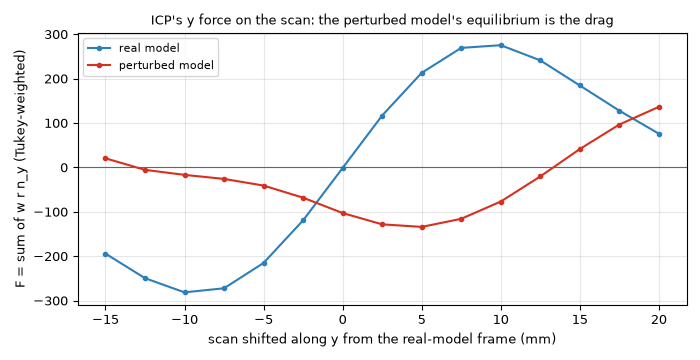

peak RSS so far: 1.16 GB


In [15]:
# Experiment 2: where does the y constraint sit, and why does the 3 cm wall stop resisting? For the scan shifted by dy along y from the real-model frame, each scan point
# is matched to the nearest model triangle; with the Tukey weight w of its point-to-plane residual r (zero beyond 2 cm), the y-gradient of ICP's cost is F(dy) = sum w r n_y
# (zero at an equilibrium; a stable one where F rises through zero) and its stiffness S(dy) = sum w n_y^2 is the y constraint each element carries.
def prep_scene(els):
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
        first.append(first[-1] + len(e.faces))
    return scene, np.concatenate(normal_list), np.array(first)


def y_constraint(prep, pts, dy):
    scene, normals, first = prep
    q = np.ascontiguousarray(pts + np.array([0, dy / 1000, 0], np.float32), dtype=np.float32)
    r = scene.compute_closest_points(o3d.core.Tensor(q))
    g, foot = r["geometry_ids"].numpy(), r["points"].numpy()
    n = normals[first[g] + r["primitive_ids"].numpy()]
    res = np.einsum("ij,ij->i", q - foot, n)
    w = np.where(np.abs(res) < TUKEY_K, (1 - (res / TUKEY_K) ** 2) ** 2, 0.0) * (np.abs(res) <= ICP_FINE_DIST)
    return g, w * res * n[:, 1], w * n[:, 1] ** 2  # per point: element, its force term, its stiffness term


P_CURVE = P_REAL[::STRIDE]
CURVE, SHARE = {}, {}
for name, els in (("real model", elements), ("perturbed model", elements_p)):
    prep = prep_scene(els)
    F, S = [], []
    for dy in DY:
        g, f, s = y_constraint(prep, P_CURVE, dy)
        F.append(f.sum()); S.append(s.sum())
        if dy == 0:
            SHARE[name] = {i: (s[g == i].sum() / s.sum(), f[g == i].sum()) for i in range(len(elements))}
    CURVE[name] = np.array(F)
    roots = [DY[k] - CURVE[name][k] * (DY[k + 1] - DY[k]) / (CURVE[name][k + 1] - CURVE[name][k]) for k in range(len(DY) - 1) if CURVE[name][k] < 0 <= CURVE[name][k + 1]]
    print(f"{name}: stable equilibrium (F rises through zero) at dy = {', '.join(f'{r:.1f}' for r in roots)} mm from the real-model frame")
del prep
print(f"\nat dy = 0 (the real-model frame): share of the y constraint (sum of w n_y^2) per element, and its force (sum of w r n_y; the total is what ICP removes by moving)")
print(f"{'element':28s}{'real model':>16s}{'perturbed model':>18s}")
shown = sorted({i for k in SHARE for i, (sh, _) in SHARE[k].items() if sh > 0.02} | set(moved_idx))
for i in shown:
    print(f"{short(i):28s}" + "".join(f"{SHARE[k][i][0]:9.1%} {SHARE[k][i][1]:+7.0f}" + (" " * 2 if k == "real model" else "") for k in SHARE) + ("   <- moved " + f"{np.linalg.norm(VEC[i]) * 100:.0f} cm" if i in moved_idx else ""))
print(f"{'the three moved walls together':28s}" + "".join(f"{sum(SHARE[k][i][0] for i in moved_idx):9.1%} {sum(SHARE[k][i][1] for i in moved_idx):+7.0f}  " for k in SHARE))
print(f"{'all elements':28s}" + "".join(f"{sum(v[0] for v in SHARE[k].values()):9.1%} {sum(v[1] for v in SHARE[k].values()):+7.0f}  " for k in SHARE))

fig, ax = plt.subplots(figsize=(7, 3.6))
for k, c in (("real model", "#2c7fb8"), ("perturbed model", "#d7301f")):
    ax.plot(DY, CURVE[k], "-o", ms=3, color=c, label=k)
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xlabel("scan shifted along y from the real-model frame (mm)"); ax.set_ylabel("F = sum of w r n_y (Tukey-weighted)")
ax.set_title("ICP's y force on the scan: the perturbed model's equilibrium is the drag", fontsize=9)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUT / "icp_pull_y_force.png", dpi=100)
plt.close(fig)
display(Image(filename=str(OUT / "icp_pull_y_force.png"), width=700))
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


## 6. Scores

Scoring is absolute: expected 1 cm moved -> **OK**, 3 cm and 10 cm moved -> **shifted**, every deleted -> **not confirmed** (missing and not visible need scanner positions, and 01 recovered none). Untouched elements have no expected verdict; they are scored only for the false-flag rate. `actual` is the run in the **frozen real-model frame** (section 4); `dragged` is the context run in the frame refined against the perturbed model (section 5).

**Sign convention.** The signed offset is the scan relative to the model, positive towards the room. A model wall moved *into* the room by d therefore reads the scan **behind** the modelled face: the median offset changes by about **-d** (for a wall with one room-facing side). With 03a's side test a partition (two room-facing sides) has all its offsets expressed along its **reference side's** normal (the side with more points), the other side's flipped, so a partition moved by d also reads one offset of about -d or +d, depending on whether the reference side is the one the wall moved towards or away from; the reference side is not recorded here, so for the 10 cm partition the sign of the change is read from the table, not predicted. The change in median offset against the baseline is printed next to the injected offset.

**False-flag rate on untouched elements** (the 05 gate's input: "at most 10 % of untouched elements are falsely flagged shifted or missing"): the share of the untouched elements whose perturbed-run verdict is shifted or missing. **The gate number is the absolute count**, as the roadmap words it: the untouched elements whose perturbed-run verdict is shifted or missing, divided by the untouched elements. The **new** count (only those not already shifted in the baseline on the real model) is context, not the gate. Missing never occurs here.


In [16]:
CHANGE = {c["global_id"]: c for c in changes}
def expected_of(c):
    if c["change"] == "not_built":
        return "not confirmed"
    return EXPECTED_MOVED[round(float(np.linalg.norm(c["offset_m"])), 3)]

SCORES = {}
for variant in ("oracle_labels", "no_labels"):
    rows = []
    for base, run, drag in zip(BASE[variant], RUN[variant], RUN_DRAG[variant]):
        g = run["global_id"]
        assert base["global_id"] == g == drag["global_id"]
        c = CHANGE.get(g)
        exp = expected_of(c) if c else ""
        rows.append(dict(global_id=g, ifc_class=run["ifc_class"], name=run["name"], change=c["change"] if c else "",
                         injected_offset_mm=round(float(np.linalg.norm(c["offset_m"])) * 1000, 1) if c and c["offset_m"] else "",
                         expected=exp, actual=run["verdict"], baseline=base["verdict"], point_count=run["point_count"],
                         baseline_point_count=base["point_count"], median_signed_offset_mm=run["median_mm"], baseline_median_mm=base["median_mm"], share_within_tol=run["share_within_tol"], baseline_share_within_tol=base["share_within_tol"],
                         median_change_mm=run["median_mm"] - base["median_mm"], reason=run["reason"], actual_dragged_frame=drag["verdict"],
                         correct=(run["verdict"] == exp) if c else ""))
    SCORES[variant] = rows
    perturbed = [r for r in rows if r["change"]]
    print(f"\n=== {variant}: perturbed elements (expected vs actual) ===")
    print(f"{'change':9s} {'element':26s} {'inj.':>6s} {'expected':>13s} {'actual':>13s} {'dragged':>13s} {'baseline':>13s} {'points':>8s} {'median':>9s} {'baseline':>9s} {'change':>9s} {'in tol':>7s} {'(base)':>7s}  ok  reason")
    for r in perturbed:
        print(f"{r['change']:9s} {(r['ifc_class'][3:12] + ' ' + r['name'][-10:]):26s} {str(r['injected_offset_mm']):>6s} {r['expected']:>13s} {r['actual']:>13s} {r['actual_dragged_frame']:>13s} {r['baseline']:>13s} "
              f"{r['point_count']:8,d} {r['median_signed_offset_mm']:7.1f}mm {r['baseline_median_mm']:7.1f}mm {r['median_change_mm']:7.1f}mm {r['share_within_tol']:7.0%} {r['baseline_share_within_tol']:7.0%}  {'yes' if r['correct'] else 'NO ':3s} {r['reason']}")
    wrong = [r for r in perturbed if not r["correct"]]
    print(f"correct: {len(perturbed) - len(wrong)} of {len(perturbed)}; wrong:")
    for r in wrong:
        print(f"  {r['change']} {r['ifc_class'][3:]} {r['name'][-26:]}: expected {r['expected']}, got {r['actual']} ({r['reason'] or 'consistent offset'}; baseline {r['baseline']})")
    untouched = [r for r in rows if not r["change"]]
    flagged = [r for r in untouched if r["actual"] in ("shifted", "missing")]
    new = [r for r in flagged if r["baseline"] != "shifted"]
    verdict_change = [r for r in untouched if r["actual"] != r["baseline"]]
    print(f"untouched elements: {len(untouched)}; GATE number, flagged shifted or missing: {len(flagged)} ({len(flagged) / len(untouched):.1%}); context, of which new "
          f"(not shifted in the baseline): {len(new)} ({len(new) / len(untouched):.1%}); untouched elements whose verdict differs from the baseline: {len(verdict_change)}")
    for r in flagged:
        print(f"  flagged: {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {r['actual']} (baseline {r['baseline']}, median {r['median_signed_offset_mm']:.1f} mm)")
    for r in verdict_change:
        print(f"  differs from baseline: {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {r['baseline']} -> {r['actual']}")
    flagged_d = [r for r in untouched if r["actual_dragged_frame"] in ("shifted", "missing")]
    print(f"context, dragged frame: perturbed elements right {sum(r['actual_dragged_frame'] == r['expected'] for r in perturbed)} of {len(perturbed)}; untouched flagged shifted or missing {len(flagged_d)} ({len(flagged_d) / len(untouched):.1%}), "
          f"verdict differs from the baseline {sum(r['actual_dragged_frame'] != r['baseline'] for r in untouched)}")
    for r, d in zip(rows, RUN_DRAG[variant]):
        if not r["change"] and d["verdict"] in ("shifted", "missing"):
            print(f"  flagged in the dragged frame: {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {d['verdict']} (baseline {r['baseline']}, median {d['median_mm']:.1f} mm, {d['point_count']:,} points, reason in the frozen frame: {r['reason'] or '-'})")
    windows = [r for r in rows if r["ifc_class"] == "IfcWindow" and HOST.get(r["global_id"]) in moved_guids and r["baseline"] == "OK"]
    print(f"collateral: windows OK in the baseline and hosted by a moved wall: {len(windows)}; still OK in the frozen frame: {sum(r['actual'] == 'OK' for r in windows)}; in the dragged frame: {sum(r['actual_dragged_frame'] == 'OK' for r in windows)}")


=== oracle_labels: perturbed elements (expected vs actual) ===
change    element                      inj.      expected        actual       dragged      baseline   points    median  baseline    change  in tol  (base)  ok  reason
not_built Door 30:1044681                   not confirmed not confirmed not confirmed not confirmed        0     nanmm    19.9mm     nanmm      0%     37%  yes too few points
not_built Slab  60:911079                   not confirmed not confirmed not confirmed            OK        0     nanmm     5.4mm     nanmm      0%     98%  yes too few points
not_built WallStand nca:919433              not confirmed not confirmed not confirmed not confirmed        0     nanmm     0.2mm     nanmm      0%     89%  yes too few points
moved     WallStand all:961571         10.0            OK not confirmed not confirmed not confirmed  107,778   -11.8mm    -1.8mm   -10.0mm     87%     94%  NO  inconsistent offsets
moved     WallStand all:973242         30.0       shifted      

### Why the median of a moved wall does not follow the injected offset

A median is a poor locator when the offsets are a mixture. The table shows the spread of each moved wall's offsets (element-class points that are counted, percentiles) before and after (the frozen frame), how many of its faces are room-facing (a face counts once per side, along the wall's thickness axis), and how many of its band points the side test left out as the back of the wall, how many the junction margin left out (within `JUNCTION` of another element), and how many it could not decide (ambiguous: the nearest room-facing face decides, folding included).


In [17]:
SIDES = {}
print(f"{'wall':26s} {'injected':>9s} {'room-facing sides':>18s}   {'offsets, mm (p10 / p25 / p50 / p75 / p90)':>44s}   {'reference':>9s} {'back of wall':>12s} {'at junction':>11s} {'ambiguous':>9s}")
for i, d in zip(moved_idx, MOVE_M):
    e = elements[i]
    n = np.asarray(mesh_of(e).triangle_normals)[room_facing(e, box_lo, box_hi)]
    axis = int(np.argmax(np.abs(OFFSETS[e.global_id])))
    sides = len({int(np.sign(v)) for v in n[:, axis] if abs(v) > 0.5})
    SIDES[i] = sides
    for label, A, els in (("baseline", A_REAL, elements), ("perturbed", A_PERT, elements_p)):
        idx = A.points_of[i]
        idx = idx[unmasked[idx] & is_element_class[idx]] if label == "perturbed" else idx[is_element_class[idx]]
        pct = np.percentile(A.signed[idx] * 1000, [10, 25, 50, 75, 90])
        w = A.walls[i]
        print(f"{META[e.global_id]['name'][-10:]:12s} {label:9s} {d * 1000:6.0f} mm {sides:12d} side(s)   " + " / ".join(f"{v:6.0f}" for v in pct)
              + f"   {('+' if w['ref'] > 0 else '-') + 'xy'[w['axis']]:>9s} {w['n_dropped']:12,d} {A.junction_n[i]:11,d} {w['n_ambiguous'] / w['n_band']:9.0%}")
# What a pure shift would do: the baseline's own offsets of each one-sided moved wall, shifted by the injected change (-d, the sign convention of section 6), against the rule
print(f"\nthe baseline's offsets of each one-sided moved wall, shifted by -d, share within {TOL * 1000:.0f} mm (OK needs {MIN_FRAC_OK:.0%}); the share the frozen run measured")
for variant, use in (("without labels", use_all), ("with labels", use_oracle)):
    for i, d in zip(moved_idx, MOVE_M):
        if SIDES[i] != 1:
            continue
        idx = A_REAL.points_of[i]
        s = A_REAL.signed[idx[use[idx]]]
        print(f"  {variant:15s} {META[GUIDS[i]]['name'][-10:]:12s} injected {d * 1000:3.0f} mm: baseline {np.mean(np.abs(s) <= TOL):.1%}, baseline offsets shifted by -d {np.mean(np.abs(s - d) <= TOL):.1%}, "
              f"frozen run {RUN['no_labels' if variant == 'without labels' else 'oracle_labels'][i]['share_within_tol']:.1%}")


wall                        injected  room-facing sides      offsets, mm (p10 / p25 / p50 / p75 / p90)   reference back of wall at junction ambiguous
all:961571   baseline      10 mm            1 side(s)       -5 /     -3 /     -2 /     -0 /      2          +y      149,161      29,367       13%
all:961571   perturbed     10 mm            1 side(s)      -15 /    -13 /    -12 /    -10 /     -8          +y      140,936      29,014       15%
all:973242   baseline      30 mm            1 side(s)       -6 /     -5 /     -4 /     -3 /     -2          -y      151,613      35,311        9%
all:973242   perturbed     30 mm            1 side(s)      -36 /    -35 /    -34 /    -33 /    -32          -y      137,988      37,716       11%
all:978670   baseline     100 mm            2 side(s)       53 /     56 /     65 /     82 /     92          -y            0       3,474       97%
all:978670   perturbed    100 mm            2 side(s)      -55 /    -52 /     55 /     70 /     89          -y          

  without labels  all:961571   injected  10 mm: baseline 68.0%, baseline offsets shifted by -d 62.9%, frozen run 60.6%


  without labels  all:973242   injected  30 mm: baseline 81.1%, baseline offsets shifted by -d 4.5%, frozen run 4.4%
  with labels     all:961571   injected  10 mm: baseline 94.4%, baseline offsets shifted by -d 87.2%, frozen run 87.1%
  with labels     all:973242   injected  30 mm: baseline 98.1%, baseline offsets shifted by -d 0.7%, frozen run 0.7%


## 7. Outputs

`scores_oracle_labels.csv` and `scores_no_labels.csv`: one row per room element (35), `global_id, ifc_class, name, change, injected_offset_mm, expected, actual, baseline, point_count, baseline_point_count, median_signed_offset_mm, baseline_median_mm, median_change_mm, share_within_tol, baseline_share_within_tol, reason, correct, actual_dragged_frame`. `expected` and `correct` are empty for untouched elements; `actual` (perturbed run, frozen real-model frame) and `baseline` (real model, 03a's verdict) are always set; `actual_dragged_frame` is the context run of section 5. The figure is a top-down plan (a cut at chest height, z 1.15 m): the perturbed elements drawn thick, green where the verdict is the expected one and red where not, untouched elements flagged shifted in orange, the rest grey; the room box dashed.


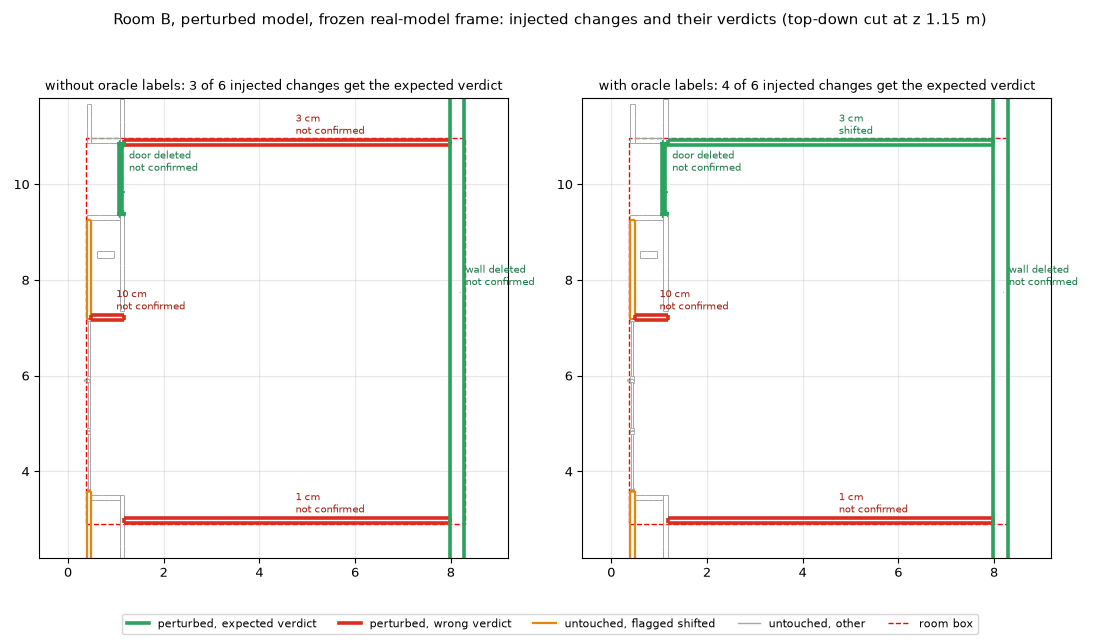

wrote craslabbim_perturbed.ifc icp_pull_y_force.png manifest.json scores_no_labels.csv scores_oracle_labels.csv scores_top_down.png
peak RSS 1.16 GB, notebook run 276 s


In [18]:
FIELDS = ["global_id", "ifc_class", "name", "change", "injected_offset_mm", "expected", "actual", "baseline", "point_count", "baseline_point_count",
          "median_signed_offset_mm", "baseline_median_mm", "median_change_mm", "share_within_tol", "baseline_share_within_tol", "reason", "correct", "actual_dragged_frame"]
for variant, rows in SCORES.items():
    with open(OUT / f"scores_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 2) if isinstance(v, float) else v) for k, v in {k: r[k] for k in FIELDS}.items()})


def section(els, axis, value):
    # Line segments where the plane axis == value cuts the elements' triangles: (n, 2, 2), two end points in the other two axes.
    keep_axes = [i for i in range(3) if i != axis]
    out = []
    for e in els:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep_axes] + t[:, None] * (tri[idx, j][:, keep_axes] - tri[idx, i][:, keep_axes])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


LABEL = {"moved": lambda c: f"{np.linalg.norm(c['offset_m']) * 100:.0f} cm", "not_built": lambda c: {"IfcDoor": "door", "IfcSlab": "slab", "IfcWallStandardCase": "wall"}[c["ifc_class"]] + " deleted"}  # a class that is not listed raises
fig, axs = plt.subplots(1, 2, figsize=(11, 6.4))
for ax, (variant, title) in zip(axs, (("no_labels", "without oracle labels"), ("oracle_labels", "with oracle labels"))):
    rows = {r["global_id"]: r for r in SCORES[variant]}
    ax.add_collection(LineCollection(section(elements_p, 2, Z_CUT), colors="0.65", linewidths=0.7))
    flagged = [e for e in elements_p if e.global_id not in CHANGE and rows[e.global_id]["actual"] == "shifted"]
    if flagged:
        ax.add_collection(LineCollection(section(flagged, 2, Z_CUT), colors="#e6850e", linewidths=1.6))
    for g, c in CHANGE.items():
        e = by_id_p[g]
        ok = rows[g]["correct"]
        cut = section([e], 2, Z_CUT)
        if len(cut):
            ax.add_collection(LineCollection(cut, colors="#2ca25f" if ok else "#d7301f", linewidths=2.6))
        x, y = (e.vertices[:, :2].min(0) + e.vertices[:, :2].max(0)) / 2
        ax.annotate(f"{LABEL[c['change']](c)}\n{rows[g]['actual']}", (x, y), xytext=(6, 6), textcoords="offset points", fontsize=7,
                    color="#1b7a45" if ok else "#a31d10", arrowprops=dict(arrowstyle="-", lw=0.5, color="0.4"))
    ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
    ax.set_xlim(-0.6, 9.2); ax.set_ylim(2.2, 11.8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    n_ok = sum(bool(rows[g]["correct"]) for g in CHANGE)
    ax.set_title(f"{title}: {n_ok} of {len(CHANGE)} injected changes get the expected verdict", fontsize=9)
fig.legend(handles=[plt.Line2D([], [], color="#2ca25f", lw=2.6, label="perturbed, expected verdict"), plt.Line2D([], [], color="#d7301f", lw=2.6, label="perturbed, wrong verdict"),
                    plt.Line2D([], [], color="#e6850e", lw=1.6, label="untouched, flagged shifted"), plt.Line2D([], [], color="0.65", lw=1, label="untouched, other"),
                    plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")], loc="lower center", ncol=5, fontsize=8)
fig.suptitle("Room B, perturbed model, frozen real-model frame: injected changes and their verdicts (top-down cut at z 1.15 m)")
plt.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(OUT / "scores_top_down.png", dpi=100)  # 1100 x 640 px
plt.close(fig)
display(Image(filename=str(OUT / "scores_top_down.png"), width=1100))
print("wrote", *sorted(p.name for p in OUT.iterdir()))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")

## Answer

Room B of the CRAS lab, 35 elements, 03a's verdict logic and parameters unchanged (including the wall side test and junction margin of issue #17), a perturbed model with six recorded changes (`outputs/03b/manifest.json`), now scored in the **real model's refined frame** with **geometric masks** and deleted elements that each have points to remove (issue #18). **Without oracle labels 3 of 6 injected changes get the verdict they should, with labels 4 of 6**: all three deleted elements are not confirmed; of the three moves only the 3 cm move of `Drywall:9732` is right, and only with labels. The false-flag rate on untouched elements is **1 of 29 (3.4 %)** in both variants, and that one wall (`Drywall:9625`) was already shifted in the baseline. The moves are read as injected now (the median of each moved wall changes by the injected offset), so what still fails is in 03a's wall model and in the control, not in the frame. (Every number below is printed by a cell of this notebook; section numbers in brackets.)

**Design as implemented.**
- *Masks by geometry* (section 3). A deleted element's mask is the element-class scan points within `BAND` of its mesh in the real-model frame, whoever the baseline assigned them to. It was written test first: on a synthetic scene (plate X deleted, neighbour plate Y moved 8 cm away so that Y's front surface becomes nearer to X) the known answer is that the assignment-based mask leaks 441 points of Y onto X and the geometric mask leaks none. With a stand-in that returned the assignment-based mask, the assert failed ("the geometric mask leaked 441 points"; that run was a scratch run, only the green version is in the notebook); with the geometric mask it passes.
- *Frozen frame* (section 4). The perturbed run uses `T_REAL`. Reason: the test is about the comparison, not the registration; with the refinement against the perturbed model the 1 and 3 cm readings are the injected change plus a 13 mm frame error. The cost is that the run no longer shows what a real pipeline would do with a wrong model; that is reported below and as an extra column (`actual_dragged_frame`).
- *Deleted elements* (section 3). Rule: at least `MIN_POINTS` element-class points on the element by the geometric mask. The door is kept (it qualifies). The column is replaced (0 points). The element that is OK in the baseline is the floor slab `Slab 911079` (the only unmoved, non-door element, not hosted by a moved wall, with enough points and area in the box that is OK in any baseline variant: OK with labels, not confirmed without; all 5 OK windows are hosted by moved walls and excluded). The clutter-hidden wall is `919433` (`...pintura branca`): the highest share of its room-facing face area with clutter-class points in front of it between 3 cm and 1 m (28.7 %; 18.0 % at 0.5 m; the distances are a judgement call, the 0.5 m ranking has the same winner) among eligible unmoved walls; `Drywall:9790`, the first version's choice, is next at 16.4 %.
- *Pre-registration, honestly.* The rule was rewritten after the first version's perturbed verdicts on its old cases (door, column, `Drywall:9790`) had been seen, because those cases tested little. For the new cases it was fixed on baseline data only (point counts, baseline verdicts, the clutter measure), before any perturbed verdict for them existed.
- *What each deleted element tests.* With labels all three read "too few points" by construction (the mask removes every element-class point near them): that tests the mask and the point-count rule, not the offset logic; the slab also tests that the verdict falls from OK. Without labels the door and the slab leave clutter and unassigned points (counts below) and read "inconsistent offsets"; for the hidden wall that is the whole test: that clutter left in front of a deleted wall does not turn into OK or shifted. The occlusion is measured but is not tied to a verdict effect (no second, less occluded wall to compare with), and `Drywall:9615`, more occluded (31.3 %) than the chosen wall, was excluded because it is a moved wall. The slab and `919433` were not OK without labels in the baseline, so in that variant they are not flips from OK.

**Mask leak, before and after** (element-class points that land on each deleted element in the perturbed run and that the mask did not take; counted points, by baseline owner) [section 4]:

| deleted | assignment-based mask (before) | geometric mask (after) |
|---|---|---|
| door | 430 (all from `Drywall:9732`) | 0 |
| slab | 508 (`9615` 289, `9732` 207, `9786` 12) | 0 |
| wall `919433` | 0 | 0 |

In the dragged frame (mask still made in the real-model frame): door 2,769 -> 0, slab 598 -> 0, wall 57 -> 57 (points outside the band in the real frame, which the 13 mm frame drift brings in). The wall `919433` leaks nothing under either mask because it is not next to a moved wall, so it does not test the leak; the door and the slab do. The first version's leak figures were for other elements, in the dragged frame, and are not comparable (git history).

*What the geometric mask costs: points of other elements it also removes* [section 3] (baseline owner, of the points inside the mask; the largest three): door 16,875 (slab 6,973, `Drywall:9790` 4,511 = 8.9 % of its element-class points, `Drywall:9732` 4,173); slab 24,640 (window `1154752` 13,928 = 19.6 % of its points, `Drywall:9625` 3,592, `9615` 2,118); wall `919433` 31,825 (covering `1428995` 12,462, window `1134763` 2,719 = 60.5 % of its points, window `1133672` 2,320 = 51.2 %). In total 892,742 crop points are masked, against 831,681 with the assignment-based masks.

**The ICP pull** [section 5]. Refining against the perturbed model displaces the frame by 13.2 mm along y (x -0.3, z 0.0; rotation 0.021 degrees), as the first version found. Experiment 1 (ICP on every 8th scan point; difference along y to the real model with the same pass, mm):

| model | plain pass only | Tukey pass only | both (pipeline) |
|---|---|---|---|
| 1 cm wall only | +3.4 | +0.7 | |
| 3 cm wall only | -16.5 | +3.7 | |
| 10 cm wall only | +2.6 | 0.0 | |
| 1 cm + 3 cm walls | -12.5 | +13.2 | |
| all three moved | -12.4 | +13.2 | +13.2 |

(The check line: the same on every 8th point gives 13.2 mm, the full scan 13.2 mm; Tukey only and both are identical for the real and the all-moved model.) Experiment 2 (a one-dimensional nearest-triangle version of ICP's y force with the Tukey weights, not ICP; its equilibria, 0.0 mm for the real model and +13.3 mm for the perturbed one, match the ICP results): in the real-model frame the 1 cm wall carries 39.5 % of the room's Tukey-weighted y constraint, the 3 cm wall 48.4 %, the 10 cm partition 0.0 %, the three together 88.0 %. After the move the 3 cm wall carries 7.6 % (not zero) and its force goes from +98 to 0; the 1 cm wall carries 46.6 % and pulls with -99.
- *What the data show.* (a) The three moved walls carry most (88.0 %) of the y constraint, and the 10 cm partition none. (b) The 1 cm wall alone moves the frame only 0.7 mm: it is held by the opposite wall, which is the 3 cm one. (c) With the 3 cm move, that opposite wall's weighted constraint falls from 48.4 % to 7.6 % and its force to 0 (its 3 cm gap is larger than the 2 cm Tukey kernel, so most of its points get no weight), and the 1 cm wall, whose 1 cm gap is inside the kernel, is left unopposed: the frame ends at +13.3 mm in the sketch, +13.2 mm in ICP. (d) The pull is not additive: the single-wall results sum to 4.4 mm (0.7 + 3.7 + 0.0), the pair gives 13.2.
- *What it does not show.* My hypothesis ("the 1 cm move is inside the kernel and the moved walls carry most of the constraint") is only a part of this: the 1 cm wall's pull is held back by the 3 cm wall until that wall leaves the kernel. And the Tukey loss is not shown to be the sole cause: the plain pass, with no robust loss, also moves the frame (-16.5 mm for the 3 cm wall alone, -12.4 mm for all three), in the opposite direction; the pipeline's final result is the Tukey pass's (+13.2 mm, identical to Tukey alone). I did not test why the plain pass moves the other way, a larger kernel, or other rooms. Freezing the transform avoids all of it for this test.
- *A separate effect of the geometric masks.* If the masked points are also left out of the ICP input (as the first version did), the frame moves 35.7 mm in x and 5.4 mm in z (y 0.1 mm), because the floor slab and a long wall no longer constrain x and z. The dragged-frame run uses the whole scan for ICP for that reason.
- *Verdicts the dragged frame gives (context).* Without labels 0 / 2 / 33, with labels 0 / 3 / 32; perturbed elements right 3 of 6 / 4 of 6 (the same ones as the frozen frame); untouched flagged shifted or missing 2 of 29 (6.9 %): `Drywall:9625` (baseline shifted already, median -135.7 mm without labels) and `Drywall:9768` (`976859`: baseline not confirmed, "too few points" in the frozen frame, shifted at +94.9 mm on 8,952 points without labels; I did not trace why the frame flips it). **Collateral windows:** the 5 OK windows hosted by moved walls stay OK in the frozen frame and none of them is OK in the dragged frame, so that collateral came from the frame drag.

**Per change, frozen frame** (expected -> actual; share within 15 mm in brackets) [section 6]:

| change | expected | without labels | with labels | dragged frame (no labels / labels) |
|---|---|---|---|---|
| `Drywall:9615` moved 1 cm | OK | not confirmed (61 %) | not confirmed (87 %) | same |
| `Drywall:9732` moved 3 cm | shifted | not confirmed (4 %) | **shifted** (1 %) | not confirmed / shifted |
| `Drywall:9786` moved 10 cm | shifted | not confirmed | not confirmed | same |
| door deleted | not confirmed | **not confirmed** (4,171 points left) | **not confirmed** (0, too few) | same |
| slab deleted | not confirmed | **not confirmed** (101,274 left) | **not confirmed** (0, too few; was OK) | same |
| wall `919433` deleted | not confirmed | **not confirmed** (6,797 left) | **not confirmed** (0, too few) | same |

- *The moves read as injected.* The median of `9615` changes by -10.0 mm (-9.9 without labels) and of `9732` by -30.0 mm in the frozen frame (the printed median change next to the injected offset).
- *1 cm, `Drywall:9615`: not OK, and with its offsets it could not be.* It was 94.4 % within 15 mm in the baseline with labels (68.0 % without), 0.6 points under the 95 % OK rule. Shifting the baseline's own offsets by -10 mm gives 87.2 % (62.9 % without labels); the frozen run measured 87.1 % (60.6 %). So for this wall a 1 cm move cannot stay OK under the 95 % rule, and the roadmap's "1 cm: stays OK" is not a valid expectation for it. I did not try another wall or room, so I cannot say how a quieter wall would fare; a control needs either that or a different expectation (for example, the median change).
- *3 cm, `Drywall:9732`:* right with labels (baseline 98.1 %, after the move one cluster at -34 mm, 0.7 % within 15 mm; shifting the baseline's offsets by -30 mm gives 0.7 %). Without labels the baseline is 81.1 % and not confirmed, so it cannot come out shifted.
- *10 cm, `Drywall:9786`:* unchanged from #17: a two-sided partition whose side the scan cannot show (85 % of its points ambiguous), so the offsets stay a mixture. A 10 cm move of a 10 cm partition is a degenerate test for any nearest-face rule.
- *Deleted:* all three are correct; what that tests is in the design section above.

**Collateral and the rest.** One untouched element changes against the baseline in the frozen frame: window `1471857` (hosted by the 3 cm wall), not confirmed -> OK with labels; I did not trace why. No element is newly flagged shifted (the gate number is 1 of 29 = 3.4 %, the already-shifted `Drywall:9625`; new 0).

**What it says about the 05 gate** ("every injected change beyond tolerance gets the right verdict, and at most 10 % of untouched elements are falsely flagged shifted or missing"): the second clause passes (3.4 %). The first still fails in the frozen frame: of the two moves beyond tolerance, 0 of 2 without labels and 1 of 2 with labels. What remains: a control that can stay OK (above); walls that are OK in the baseline for the 3 cm and 10 cm moves (a fairer moved-wall choice is only baseline-OK walls; `Drywall:9732` is the only one with labels and none without, so this room cannot supply three); a partition whose side the scan can show. A real pipeline that refines against a wrong model would also meet the ICP pull; here it is reported, not fixed.

**Not checked / doubts.** Experiment 2 is a one-dimensional approximation, not ICP; experiment 1 uses every 8th point (it reproduces the full-scan 13.2 mm). The occlusion range (3 cm to 1 m) is a judgement call and I tried only 0.5 m besides it. One room only. The slab as "the OK element" rests on OK in one variant, with a small share of its surface inside the box (printed). **Runtime:** nbclient's timeout is per cell, not for the notebook; the test runs the notebook with 3,600 s per cell, and the notebook prints its own total run time on its last line.
